# AD699 Semester Project - Geneva Airbnb



## Team task split

**Hye won**
- Part 2: Prediction (Multiple Regression)
- Part 3-2: Classification Tree
- Part 4: Clustering

**Simon** 
- Part 1: Data Preparation & Exploration
- Part 3-1: KNN
- Part 3-3: Transformer

**Joint**
- Part 5: Conclusions
- Final report integration and review
- Presentation preparation


# Setup




In [102]:
import pandas as pd
import ast
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from matplotlib.patches import Patch
from wordcloud import WordCloud
from collections import Counter
import re
import folium
from folium.plugins import MarkerCluster
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sentence_transformers import SentenceTransformer
from IPython.display import Image, display
from pathlib import Path
import statsmodels.formula.api as smf
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
from sklearn.tree import plot_tree
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sns.set_theme(style='whitegrid')


# Part 1. Data Preparation & Exploration


## First look at the data


In [2]:
df = pd.read_csv('geneva_listings.csv')
# seeing all columns 
pd.set_option('display.max_columns', None)
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_name,host_since,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,42515.0,https://www.airbnb.com/rooms/42515,2.023090e+13,9/23/2023,city scrape,Rental unit in Geneva · ★4.73 · 1 bedroom · 1 ...,<b>The space</b><br />This is a private room w...,NaN,https://a0.muscache.com/pictures/10640277/ff1d...,185647,https://www.airbnb.com/users/show/185647,Noelle,7/30/2010,"Geneva, Switzerland","Hi, I am a Management consultant professional,...",within a few hours,100%,40%,f,https://a0.muscache.com/im/users/185647/profil...,https://a0.muscache.com/im/users/185647/profil...,NaN,1,1,"['email', 'phone']",t,t,NaN,Commune de Genève,NaN,46.20198,6.15672,Private room in rental unit,Private room,1,NaN,1.5 shared baths,NaN,1.0,"[""Dryer"", ""Kitchen"", ""TV with standard cable"",...",$89.00,3,1125,3,3,1125,1125,3.0,1125.0,NaN,t,28,58,88,363,9/23/2023,73,6,0,9/24/2011,7/21/2023,4.73,4.71,4.77,4.84,4.83,4.84,4.51,NaN,f,1,0,1,0,0.50
1,107438.0,https://www.airbnb.com/rooms/107438,2.023090e+13,9/23/2023,city scrape,Rental unit in Geneva · ★4.87 · 1 bedroom · 1 ...,<b>The space</b><br />Version Française et Ang...,NaN,https://a0.muscache.com/pictures/93bb00cc-03bb...,556499,https://www.airbnb.com/users/show/556499,F. M.,5/4/2011,"Geneva, Switzerland",It is a cosy furnished room with wifi connexio...,a few days or more,20%,13%,f,https://a0.muscache.com/im/users/556499/profil...,https://a0.muscache.com/im/users/556499/profil...,Passy,2,5,"['email', 'phone']",t,t,NaN,Commune de Genève,NaN,46.18905,6.16154,Private room in rental unit,Private room,1,NaN,1.5 shared baths,NaN,1.0,"[""Dishwasher"", ""Wine glasses"", ""Essentials"", ""...",$60.00,5,1125,5,5,1125,1125,5.0,1125.0,NaN,t,9,39,69,344,9/23/2023,27,0,0,5/15/2011,11/30/2019,4.87,4.90,4.76,4.76,4.76,4.57,4.57,NaN,f,1,0,1,0,0.18
2,203997.0,https://www.airbnb.com/rooms/203997,2.023090e+13,9/23/2023,city scrape,Rental unit in Geneva · ★4.90 · 1 bedroom · 1 ...,"Spacious studio with washer/dryer, Wi-fi, supe...",This is the most sought after area in Geneva: ...,https://a0.muscache.com/pictures/14163740/9392...,1001280,https://www.airbnb.com/users/show/1001280,Mike,8/21/2011,"Geneva, Switzerland","I love airbnb, both for hosting and traveling....",within an hour,100%,100%,t,https://a0.muscache.com/im/pictures/user/3bbea...,https://a0.muscache.com/im/pictures/user/3bbea...,NaN,6,12,"['email', 'phone']",t,t,"Geneva, Switzerland",Commune de Genève,NaN,46.19964,6.15580,Entire rental unit,Entire home/apt,2,NaN,1 bath,1.0,NaN,"[""TV with standard cable"", ""Free dryer \u2013 ...",$165.00,5,730,5,5,1125,1125,5.0,1125.0,NaN,t,6,6,28,28,9/23/2023,81,7,0,11/11/2012,7/23/2023,4.90,4.98,4.90,4.98,4.99,4.95,4.83,NaN,t,2,2,0,0,0.61
3,276025.0,https://www.airbnb.com/rooms/276025,2.023090e

In [3]:
df.describe()

,id,scrape_id,host_id,host_listings_count,host_total_listings_count,neighbourhood_group_cleansed,latitude,longitude,accommodates,bathrooms,bedrooms,beds,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,availability_30,availability_60,availability_90,availability_365,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
count,2.458000e+03,2.458000e+03,2.458000e+03,2458.000000,2458.000000,0.0,2458.000000,2458.000000,2458.000000,0.0,1616.000000,2423.000000,2458.000000,2458.000000,2458.000000,2458.000000,2458.000000,2458.000000,2458.000000,2458.000000,0.0,2458.000000,2458.000000,2458.000000,2458.000000,2458.000000,2458.000000,2458.000000,2011.000000,2003.000000,2003.000000,2003.000000,2003.000000,2003.000000,2003.000000,0.0,2458.000000,2458.000000,2458.000000,2458.000000,2011.000000
mean,3.347826e+17,2.023090e+13,1.462929e+08,12.274207,21.962978,NaN,46.207384,6.144258,2.683483,NaN,1.459777,1.601733,7.615134,513.373881,7.381204,8.037836,642.593572,650.510578,7.749959,647.899837,NaN,9.156631,22.530919,37.458503,148.644833,25.951993,7.615134,0.700570,4.684585,4.747713,4.695372,4.808582,4.792376,4.780359,4.593190,NaN,6.711961,5.488202,1.137510,0.012205,1.164823
std,4.072105e+17,0.000000e+00,1.661859e+08,38.877165,72.731333,NaN,0.019959,0.026763,1.547478,NaN,0.830303,1.064919,41.230849,467.789183,41.143296,41.467659,479.043186,477.380698,41.233700,476.773602,NaN,10.691491,22.728173,34.854767,136.700947,54.762091,14.750370,1.532662,0.537593,0.419357,0.461689,0.366121,0.411464,0.364732,0.485614,NaN,16.804123,15.296768,2.148299,0.109823,1.594808
min,4.251500e+04,2.023090e+13,6.783700e+04,1.000000,1.000000,NaN,46.141460,5.972910,1.000000,NaN,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,1.000000,0.000000,0.000000,0.000000,0.010000
25%,2.754973e+07,2.023090e+13,1.414569e+07,1.000000,1.000000,NaN,46.197940,6.132700,2.000000,NaN,1.000000,1.000000,1.000000,36.000000,1.000000,1.000000,99.250000,120.000000,1.000000,120.000000,NaN,0.000000,0.000000,0.000000,6.000000,1.000000,0.000000,0.000000,4.590000,4.670000,4.600000,4.760000,4.750000,4.710000,4.500000,NaN,1.000000,0.000000,0.000000,0.000000,0.220000
50%,4.944392e+07,2.023090e+13,5.738378e+07,2.000000,2.000000,NaN,46.205390,6.144440,2.000000,NaN,1.000000,1.000000,2.000000,365.000000,2.000000,2.000000,365.000000,365.000000,2.000000,365.000000,NaN,4.000000,17.000000,34.000000,98.000000,7.000000,2.000000,0.000000,4.830000,4.870000,4.820000,4.920000,4.930000,4.880000,4.690000,NaN,1.000000,1.000000,0.000000,0.000000,0.580000
75%,7.931008e+17,2.023090e+13,2.462544e+08,4.000000,6.000000,NaN,46.212540,6.156560,4.000000,NaN,2.000000,2.000000,5.000000,1125.000000,4.000000,5.000000,1125.000000,1125.000000,5.000000,1125.000000,NaN,18.000000,45.000000,72.000000,282.000000,27.000000,8.000000,1.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,4.880000,NaN,3.000000,2.000000,1.000000,0.000000,1.390000
max,9.864120e+17,2.023090e+13,5.380919e+08,375.000000,377.000000,NaN,46.351680,6.273080,16.000000,NaN,9.000000,16.000000,1100.000000,1200.000000,1100.000000,1100.000000,1200.000000,1200.000000,1100.000000,1200.000000,NaN,30.000000,60.000000,90.000000,365.000000,718.000000,156.000000,13.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,NaN,88.000000,79.000000,10.000000,1.000000,12.910000


## 1. Missing Values


### First Look


In [4]:
pd.set_option('display.max_rows', None)  # to see all rows

# count missing values per column
missing_counts = df.isnull().sum()

# keep only columns that have at least 1 missing value
cols_with_missing = missing_counts[missing_counts > 0]

cols_with_missing

description                       61
neighborhood_overview           1273
host_location                    443
host_about                      1243
host_response_time               534
host_response_rate               534
host_acceptance_rate             321
host_is_superhost                  7
host_neighbourhood              2422
neighbourhood                   1273
neighbourhood_group_cleansed    2458
bathrooms                       2458
bedrooms                         842
beds                              35
calendar_updated                2458
first_review                     447
last_review                      447
review_scores_rating             447
review_scores_accuracy           455
review_scores_cleanliness        455
review_scores_checkin            455
review_scores_communication      455
review_scores_location           455
review_scores_value              455
license                         2458
reviews_per_month                447
dtype: int64

In [5]:
# percentage of missing values per column
col_missing_pct = (df.isnull().mean() * 100).sort_values(ascending=False)
# keep only columns that have at least some missing values
col_missing_pct[col_missing_pct > 0]

license                         100.000000
neighbourhood_group_cleansed    100.000000
bathrooms                       100.000000
calendar_updated                100.000000
host_neighbourhood               98.535395
neighbourhood                    51.790073
neighborhood_overview            51.790073
host_about                       50.569569
bedrooms                         34.255492
host_response_time               21.724980
host_response_rate               21.724980
review_scores_accuracy           18.510985
review_scores_cleanliness        18.510985
review_scores_checkin            18.510985
review_scores_communication      18.510985
review_scores_location           18.510985
review_scores_value              18.510985
last_review                      18.185517
first_review                     18.185517
review_scores_rating             18.185517
reviews_per_month                18.185517
host_location                    18.022783
host_acceptance_rate             13.059398
description

### Completely empty fields


4 fields are completly empty : `bathrooms` , `license` , `neighbourhood_group_cleansed`  and `calendar_updated` 

For `bathrooms` I noticed that `bathrooms_text` has the numbers so i will simply build those numbers from the text.

In [6]:
# build bathrooms from bathrooms_text
# e.g. "1.5 shared baths" -> 1.5, "Half-bath" / "Shared half-bath" -> 0.5
df['bathrooms'] = (
    df['bathrooms_text']
      .str.lower()
      .str.extract(r'(\d+\.?\d*)')[0]
      .astype(float)
)

# half-bath has no digit in the text
df.loc[df['bathrooms_text'].str.contains('half', case=False, na=False), 'bathrooms'] = 0.5

df[['bathrooms_text', 'bathrooms']].head(10)

,bathrooms_text,bathrooms
0,1.5 shared baths,1.5
1,1.5 shared baths,1.5
2,1 bath,1.0
3,1 bath,1.0
4,1.5 baths,1.5
5,1 shared bath,1.0
6,1.5 shared baths,1.5
7,1.5 baths,1.5
8,1 bath,1.0
9,2.5 baths,2.5


For `license` there isn't much we can do and hence i will drop 
it.

In [7]:
df = df.drop(columns=['license'])

Now `neighbourhood_group_cleansed` I understand some cities group neighbourhoods into larger zones (like boroughs), but Geneva doesn't use that in this file. The canton also has no official district/borough layer; only the City of Geneva has 8 quartiers, while our `neighbourhood_cleansed` is already at the commune level and complete. So I will drop `neighbourhood_group_cleansed`

In [8]:
df = df.drop(columns=['neighbourhood_group_cleansed'])

Lastly `calendar_updated`, This would record the last update time the host would have updated calendar. I will drop it as well as we can't really do much, we can't neither impute nor make arbitrary decisions or use it in anyway later.

In [9]:
df = df.drop(columns=['calendar_updated'])

### Place / neighbourhood fields


`host_neighbourhood` is the neighbourhood the host says they live in (not necessarily where the listing is). It is missing for about 98.5% of rows, so there is almost nothing useful here. We already have a complete, cleaned listing location in `neighbourhood_cleansed`, so I will drop `host_neighbourhood`.

In [10]:
df = df.drop(columns=['host_neighbourhood'])

`neighbourhood` is what the host typed for the area. It is missing for about half the rows, and when it is filled the formatting is inconsistent (`Genève, Switzerland`, `Geneva, Switzerland`, etc.). `neighbourhood_cleansed` is complete and better for analysis, so this column might not be that useful later but for practice I will fill the blanks from `neighbourhood_cleansed` using one consistent format: `Place, Canton of Geneva, Switzerland` (exemple. `Geneva, Canton of Geneva, Switzerland`).

In [11]:
# fill missing neighbourhood from neighbourhood_cleansed, same format for all
def format_neighbourhood(cleansed):
    place = 'Geneva' if cleansed == 'Commune de Genève' else cleansed
    return f"{place}, Canton of Geneva, Switzerland"

missing_neigh = df['neighbourhood'].isna()
df.loc[missing_neigh, 'neighbourhood'] = (
    df.loc[missing_neigh, 'neighbourhood_cleansed'].map(format_neighbourhood)
)

df.loc[missing_neigh, ['neighbourhood_cleansed', 'neighbourhood']].head(10)

,neighbourhood_cleansed,neighbourhood
0,Commune de Genève,"Geneva, Canton of Geneva, Switzerland"
1,Commune de Genève,"Geneva, Canton of Geneva, Switzerland"
3,Versoix,"Versoix, Canton of Geneva, Switzerland"
5,Commune de Genève,"Geneva, Canton of Geneva, Switzerland"
8,Commune de Genève,"Geneva, Canton of Geneva, Switzerland"
10,Commune de Genève,"Geneva, Canton of Geneva, Switzerland"
11,Commune de Genève,"Geneva, Canton of Geneva, Switzerland"
13,Commune de Genève,"Geneva, Canton of Geneva, Switzerland"
14,Commune de Genève,"Geneva, Canton of Geneva, Switzerland"
15,Commune de Genève,"Geneva, Canton of Geneva, Switzerland"


`neighborhood_overview` is the host's written blurb about the area. We need it later for the word cloud. About half is missing because the host simply did not write one I will leave those blanks as they are, and the word cloud will only use the non-empty text.

In [12]:
# leave neighborhood_overview blanks as-is (word cloud will use non-empty text only)
df['neighborhood_overview'].isna().sum()

np.int64(1273)

### Host profile fields


`host_about` is the host bio and `host_location` is where the host says they live. Both are optional, so blanks are common. The assignment later uses `host_about` (with `description` and `amenities`) in a transformer model, so I will keep the columns and leave the text blanks as they are. I will also add yes/no flags (`has_host_about`, `has_host_location`) so that "did the host fill this in?" can still be used as a simple signal without inventing text.

In [13]:
# keep text as-is; add flags for whether the host filled these fields
df['has_host_about'] = df['host_about'].notna()
df['has_host_location'] = df['host_location'].notna()

df[['host_about', 'has_host_about', 'host_location', 'has_host_location']].head(10)

,host_about,has_host_about,host_location,has_host_location
0,"Hi, I am a Management consultant professional,...",True,"Geneva, Switzerland",True
1,It is a cosy furnished room with wifi connexio...,True,"Geneva, Switzerland",True
2,"I love airbnb, both for hosting and traveling....",True,"Geneva, Switzerland",True
3,"Hi, my name is Gaby! I'm a globetrotter. I spe...",True,"Geneva, Switzerland",True
4,"I love airbnb, both for hosting and traveling....",True,"Geneva, Switzerland",True
5,I love sharing a spare room in my apartment to...,True,"Geneva, Switzerland",True
6,Hello traveler. I'm a humanist consultant work...,True,رام الله,True
7,"I speak English, French, German and after 2 gl...",True,"Geneva, Switzerland",True
8,I am glad to welcome you in our cozy little ap...,True,"Geneva, Switzerland",True
9,Je mets mon chez-moi à disposition lorsque je ...,True,"Geneva, Switzerland",True


`description` is the main listing write-up. Only about 2.5% is missing, and the assignment also uses this column later in the transformer model. I will leave the blanks as they are there are few of them, and filling fake listing text would not be honest.

In [14]:
# leave description blanks as-is
df['description'].isna().sum()

np.int64(61)

`host_is_superhost` says whether the host has the Superhost badge (`t` / `f`). Only 7 values are missing. Most hosts are not Superhosts (`f` is by far the most common), so I will fill those 7 with `f`.

In [15]:
# most hosts are not superhosts, so fill the 7 missing with 'f'
print(df['host_is_superhost'].value_counts(dropna=False))
df['host_is_superhost'] = df['host_is_superhost'].fillna('f')
df['host_is_superhost'].isna().sum()

host_is_superhost
f      1977
t       474
NaN       7
Name: count, dtype: int64


np.int64(0)

### Host response / acceptance fields


`host_response_time`, `host_response_rate` and `host_acceptance_rate` measure how responsive / bookable a host is. Blanks here usually mean Airbnb did not show the metric (not enough activity), not that the rate is 0.

Looking at the assignment, Classification Part II asks us to build a classification tree that predicts `host_response_time`, so we must keep that column. The rate columns can also be useful later as predictors. I will therefore keep all three and leave the blanks as they are inventing a response time or an average % would create fake host behavior. When we build the classification tree, we can simply use the rows where `host_response_time` is known.

In [16]:
# keep these columns; leave blanks as-is (needed later for classification)
df[['host_response_time', 'host_response_rate', 'host_acceptance_rate']].isna().sum()

host_response_time      534
host_response_rate      534
host_acceptance_rate    321
dtype: int64

### Listing layout fields (bedrooms & beds)


`bedrooms` is missing for about a third of listings, especially private rooms and shared rooms (hosts often skip it there). I will fill missing bedrooms with the typical value for that `room_type` (the median). For shared rooms every value is missing, so there is no median to learn from I will use 1 as a simple typical value.

In [17]:
# typical bedrooms by room_type
bedrooms_by_room_type = df.groupby('room_type')['bedrooms'].median()
print(bedrooms_by_room_type)

df['bedrooms'] = df['bedrooms'].fillna(df['room_type'].map(bedrooms_by_room_type))
# shared rooms have no observed bedrooms -> use 1
df['bedrooms'] = df['bedrooms'].fillna(1)

df['bedrooms'].isna().sum()

room_type
Entire home/apt    1.0
Hotel room         1.0
Private room       1.0
Shared room        NaN
Name: bedrooms, dtype: float64


np.int64(0)

`beds` is only missing for 35 rows. Using `accommodates` directly as the number of beds would be wrong (a place can accommodate 4 guests with only 2 beds). So I will fill missing beds with the **median number of beds among listings that accommodate the same number of guests**. If anything is still missing after that, I fall back to the overall median.

In [18]:
# median beds for each accommodates level (safer than using accommodates itself as beds)
beds_by_accommodates = df.groupby('accommodates')['beds'].median()
print(beds_by_accommodates)

df['beds'] = df['beds'].fillna(df['accommodates'].map(beds_by_accommodates))
df['beds'] = df['beds'].fillna(df['beds'].median())

df['beds'].isna().sum()

accommodates
1      1.0
2      1.0
3      2.0
4      2.0
5      3.0
6      3.0
7      4.5
8      5.0
9      6.0
10     6.0
11     8.5
12     8.0
15     9.0
16    16.0
Name: beds, dtype: float64


np.int64(0)

### Review fields


`first_review`, `last_review`, `review_scores_*` and `reviews_per_month` are missing together when a listing has **0 reviews**. That is not a random hole if nobody reviewed the place yet, there are simply no scores or review dates to show. I will leave these blanks as they are. Filling average stars for never-reviewed listings would make new listings look artificially good. Later, for modeling, we can use `number_of_reviews` and/or focus on listings that already have reviews.

In [19]:
# confirm review missings line up with 0 reviews
review_cols = [
    'first_review', 'last_review', 'review_scores_rating',
    'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin',
    'review_scores_communication', 'review_scores_location', 'review_scores_value',
    'reviews_per_month'
]

print('rating missing & 0 reviews:', ((df['review_scores_rating'].isna()) & (df['number_of_reviews'] == 0)).sum())
print('rating missing & >0 reviews:', ((df['review_scores_rating'].isna()) & (df['number_of_reviews'] > 0)).sum())
df[review_cols].isna().sum()
# leave review blanks as-is

rating missing & 0 reviews: 447
rating missing & >0 reviews: 0


first_review                   447
last_review                    447
review_scores_rating           447
review_scores_accuracy         455
review_scores_cleanliness      455
review_scores_checkin          455
review_scores_communication    455
review_scores_location         455
review_scores_value            455
reviews_per_month              447
dtype: int64

### Check what is still missing


In [20]:
# remaining missing values after cleaning
missing_after = df.isnull().sum()
missing_after = missing_after[missing_after > 0].sort_values(ascending=False)
missing_after

neighborhood_overview          1273
host_about                     1243
host_response_time              534
host_response_rate              534
review_scores_cleanliness       455
review_scores_value             455
review_scores_location          455
review_scores_communication     455
review_scores_checkin           455
review_scores_accuracy          455
last_review                     447
reviews_per_month               447
review_scores_rating            447
first_review                    447
host_location                   443
host_acceptance_rate            321
description                      61
dtype: int64

### Short summary of what we did

Our Geneva Airbnb data had missing values for different reasons, so we did not treat every column the same way. Completely empty fields (`license`, `neighbourhood_group_cleansed`, `calendar_updated`) and nearly empty `host_neighbourhood` were dropped, while `bathrooms` was rebuilt from `bathrooms_text`. For place fields, we filled `neighbourhood` from `neighbourhood_cleansed` in a consistent format for practice, and left `neighborhood_overview` blank for the word cloud. Host text fields (`host_about`, `host_location`, `description`) were kept because the assignment uses them later; we added yes/no flags for the first two and left text blanks alone. Layout gaps were filled carefully (`bedrooms` by `room_type`, `beds` by median beds within each `accommodates` level), `host_is_superhost` was filled with the majority value `f`, and response/review blanks were left as-is because they mean "unknown" or "no reviews yet" inventing values there would be misleading, and `host_response_time` is needed later for the classification tree.

## 2. Summary Statistics


I am using `neighbourhood_cleansed` and not `neighbourhood` because it is the clean complete one. Looking at the counts, Commune de Genève alone is about 72% of all listings and a lot of other communes only have a few. If I compare all 40 communes like that, the small ones will look weird just because the sample is tiny. The assignment even says we can use top_n or combine groups when there are many levels.

So I will do two approaches. First I keep all communes but I always show n (how many listings) next to the stats, so we do not over interpret a commune with 2 listings. Second I also make a simpler 3 area grouping so the comparisons are more stable.

In [21]:
# how listings are spread across communes (n matters a lot here)
area_counts = df['neighbourhood_cleansed'].value_counts()
area_share = (df['neighbourhood_cleansed'].value_counts(normalize=True) * 100).round(1)

area_overview = pd.DataFrame({'n': area_counts, 'share_pct': area_share})
area_overview

,n,share_pct
neighbourhood_cleansed,,
Commune de Genève,1774,72.2
Vernier,72,2.9
Grand-Saconnex,71,2.9
Carouge,65,2.6
Lancy,54,2.2
Versoix,47,1.9
Chêne-Bougeries,46,1.9
Thônex,46,1.9
Meyrin,41,1.7


### Cleaning `price` first

`price` is written like `$89.00` in the file. To compute medians by area I need a number, so I remove the `$` and the commas and turn it into a float (ex: 89.0).


In [22]:
# "$89.00" -> 89.0
df['price'] = (
    df['price']
      .astype(str)
      .str.replace('$', '', regex=False)
      .str.replace(',', '', regex=False)
      .astype(float)
)

df['price'].describe()

count     2458.000000
mean       174.024817
std        611.108033
min         20.000000
25%         82.000000
50%        114.500000
75%        163.000000
max      25000.000000
Name: price, dtype: float64

### Amenity count

`amenities` is a long text list so it is hard to compare as is by area. I just create `amenity_count` which is how many amenities are listed for that place. Then I can take a median by area easily.


In [23]:
def count_amenities(x):
    try:
        return len(ast.literal_eval(x))
    except (ValueError, SyntaxError, TypeError):
        return 0

df['amenity_count'] = df['amenities'].apply(count_amenities)
df['amenity_count'].describe()

count    2458.000000
mean       26.508950
std        15.165111
min         0.000000
25%        13.000000
50%        25.000000
75%        37.000000
max        80.000000
Name: amenity_count, dtype: float64

### 3 area grouping

I also wanted a simpler split than 40 communes. Just Genève vs the rest could work, but I think it hides too much. Places by the lake or smaller villages do not really feel the same as dense suburbs like Carouge or Vernier.

So I go with 3 classes and I keep Commune de Genève alone as the city:
- Genève city = `Commune de Genève`
- Inner suburbs = the denser communes right around the city (Carouge, Lancy, Vernier, Grand-Saconnex, Meyrin, Onex, Chêne-Bourg, Chêne-Bougeries, Thônex, Plan-les-Ouates)
- OUTER = everything else (lake shore, smaller villages, more rural communes)

Like this each group has enough listings for the medians to make more sense. I still keep the full commune column for the first approach.

One thing we thought about: Commune de Genève is huge (~72% of listings), so we could split the city itself into 2, 3 or 4 smaller pieces (for example the official sections Cité / Eaux-Vives / Petit-Saconnex / Plainpalais, or just lat/long cuts). We checked quickly and the price differences inside the city are real but not that big, so for now we leave the 3 classes as they are. If later a model or a plot needs more detail inside the mega class, we can come back to this.


In [24]:
inner_suburbs = [
    'Carouge', 'Lancy', 'Vernier', 'Grand-Saconnex', 'Meyrin',
    'Onex', 'Chêne-Bourg', 'Chêne-Bougeries', 'Thônex', 'Plan-les-Ouates'
]

def map_area_group(commune):
    if commune == 'Commune de Genève':
        return 'Genève city'
    if commune in inner_suburbs:
        return 'Inner suburbs'
    return 'OUTER'

df['area_group'] = df['neighbourhood_cleansed'].map(map_area_group)

# always show n
df['area_group'].value_counts()

area_group
Genève city      1774
Inner suburbs     459
OUTER             225
Name: count, dtype: int64

### Stats I will compute

For both the communes and `area_group` I compute:
1. n and share of listings
2. median price
3. median number_of_reviews
4. mean and median review_scores_rating, but only on listings that already have a rating
5. median beds
6. median amenity_count

Quick note on reviews. If I just summed all reviews, Genève would always look huge only because it has way more listings. Median reviews per listing is fairer because each listing counts once. Tiny communes can still look extreme by chance, that is why I keep n next to everything and why I also look at the 3 groups.

I use `review_scores_rating` because it is the overall score. The assignment does not ask for a specific review column here. I keep both the mean and the median rating so if one area has a few crazy low or high scores we can see it (mean moves more, median is more stable).


#### Approach 1: stats by every commune (with n)


In [25]:
def area_summary(df, group_col):
    # summary stats by area, always including n
    g = df.groupby(group_col, dropna=False)
    rated = df[df['review_scores_rating'].notna()].groupby(group_col)['review_scores_rating']

    out = pd.DataFrame({
        'n': g.size(),
        'share_pct': (g.size() / len(df) * 100).round(1),
        'median_price': g['price'].median().round(1),
        'median_reviews': g['number_of_reviews'].median(),
        'mean_rating_reviewed': rated.mean().round(2),
        'median_rating_reviewed': rated.median().round(2),
        'median_beds': g['beds'].median(),
        'median_amenity_count': g['amenity_count'].median(),
    })

    return out.sort_values('n', ascending=False)

stats_by_commune = area_summary(df, 'neighbourhood_cleansed')
stats_by_commune

,n,share_pct,median_price,median_reviews,mean_rating_reviewed,median_rating_reviewed,median_beds,median_amenity_count
neighbourhood_cleansed,,,,,,,,
Commune de Genève,1774,72.2,119.0,9.0,4.70,4.81,1.0,26.0
Vernier,72,2.9,80.0,6.0,4.39,4.78,1.0,24.0
Grand-Saconnex,71,2.9,99.0,6.0,4.66,4.89,1.0,25.0
Carouge,65,2.6,110.0,4.0,4.64,4.80,1.0,26.0
Lancy,54,2.2,99.5,3.0,4.55,4.87,1.0,27.0
Versoix,47,1.9,85.0,3.0,4.72,4.73,1.0,22.0
Chêne-Bougeries,46,1.9,120.0,2.5,4.43,4.84,1.0,26.0
Thônex,46,1.9,77.5,2.0,4.78,4.88,1.5,16.5
Meyrin,41,1.7,97.0,8.0,4.65,4.88,1.0,23.0


Communes with n = 1, 2 or 3 can show crazy medians. That is mostly sample size, not a real story. Below I keep the same stats but only for communes with at least 20 listings, still with n.

In [26]:
# easier to read: communes with at least 20 listings
stats_by_commune_top = stats_by_commune[stats_by_commune['n'] >= 20]
stats_by_commune_top

,n,share_pct,median_price,median_reviews,mean_rating_reviewed,median_rating_reviewed,median_beds,median_amenity_count
neighbourhood_cleansed,,,,,,,,
Commune de Genève,1774,72.2,119.0,9.0,4.70,4.81,1.0,26.0
Vernier,72,2.9,80.0,6.0,4.39,4.78,1.0,24.0
Grand-Saconnex,71,2.9,99.0,6.0,4.66,4.89,1.0,25.0
Carouge,65,2.6,110.0,4.0,4.64,4.80,1.0,26.0
Lancy,54,2.2,99.5,3.0,4.55,4.87,1.0,27.0
Versoix,47,1.9,85.0,3.0,4.72,4.73,1.0,22.0
Chêne-Bougeries,46,1.9,120.0,2.5,4.43,4.84,1.0,26.0
Thônex,46,1.9,77.5,2.0,4.78,4.88,1.5,16.5
Meyrin,41,1.7,97.0,8.0,4.65,4.88,1.0,23.0


#### Approach 2: same stats on the 3 area groups


In [27]:
stats_by_area_group = area_summary(df, 'area_group')
# put groups in a readable order
stats_by_area_group = stats_by_area_group.reindex(['Genève city', 'Inner suburbs', 'OUTER'])
stats_by_area_group

,n,share_pct,median_price,median_reviews,mean_rating_reviewed,median_rating_reviewed,median_beds,median_amenity_count
area_group,,,,,,,,
Genève city,1774,72.2,119.0,9.0,4.70,4.81,1.0,26.0
Inner suburbs,459,18.7,98.0,4.0,4.58,4.86,1.0,24.0
OUTER,225,9.2,116.0,3.0,4.77,4.95,1.0,24.0


### Takeaways

The first thing that stands out is how unbalanced the map is. Genève city has about 72% of listings (n=1774), inner suburbs about 19% (n=459), and OUTER about 9% (n=225). That is why I keep n next to the stats. A median from 3 listings is not the same as one from 1774.

For the actual differences, median price is higher in the city (about 119) and in OUTER (about 116), and lower in the inner suburbs (about 98). Same idea when I look at communes with enough data: Cologny is more expensive, Vernier and Thônex are cheaper. Median reviews per listing are higher in the city (9) than in the inner suburbs (4) and OUTER (3). That is already per listing so it is not just because the city has more Airbnbs. Ratings on reviewed listings are all high (around 4.6 to 4.8). I also look at median rating next to the mean to check for big outliers. Mean and median do stay close, the average is not being dragged by a few weird scores maybe a few one stars brings the mean down (which could be expected for airbnbs listings reviews) but we can't confirm that without verifications. Beds are basically 1 in every group and amenity counts are close too (city a bit higher, 26 vs 24). Overall most listings are in the city, price and review activity change a bit by area, but the size of the place and the amenities do not look that different across the three groups.


## 3. Data Visualization



Here I want plots that say something about the regions, not just pretty charts. I reuse the same variables as in the summary stats (price, reviews, rating, beds, amenity_count) and the 3 area groups. I also clean `host_response_time` properly because one plot uses it.

I make more than 5 plot types on purpose. The assignment asks for at least 5 different types and each one has to be about the city and its regions.

In [28]:
# for price plots: keep a capped version so one crazy listing does not crush the chart
price_cap = df['price'].quantile(0.95)
df['price_plot'] = df['price'].clip(upper=price_cap)
print('price 95th percentile used as plot cap:', round(price_cap, 1))

price 95th percentile used as plot cap: 350.2


### Clean `host_response_time` for later

Airbnb uses 4 clear levels. Missing usually means Airbnb did not show a response time, so I put those in `unknown` instead of dropping them. I also force a fixed order from fastest to slowest so the plots stay readable.


In [29]:
response_order = [
    'within an hour',
    'within a few hours',
    'within a day',
    'a few days or more',
    'unknown',
]

df['host_response_time_clean'] = (
    df['host_response_time']
      .fillna('unknown')
      .replace({
          'within an hour': 'within an hour',
          'within a few hours': 'within a few hours',
          'within a day': 'within a day',
          'a few days or more': 'a few days or more',
      })
)

# keep only expected labels (safety)
df.loc[~df['host_response_time_clean'].isin(response_order), 'host_response_time_clean'] = 'unknown'

df['host_response_time_clean'] = pd.Categorical(
    df['host_response_time_clean'],
    categories=response_order,
    ordered=True,
)

df['host_response_time_clean'].value_counts(dropna=False)

host_response_time_clean
within an hour        1023
unknown                534
within a few hours     496
within a day           272
a few days or more     133
Name: count, dtype: int64

### Maps of the communes

I load the official Geneva commune boundaries (SITG open data). In that file the city is split into 4 sections (Cité, Eaux-Vives, Petit-Saconnex, Plainpalais), but in our Airbnb data it is one label `Commune de Genève`, so I merge those 4 polygons into one.

First map: color by our 3 classes (Genève city / Inner suburbs / OUTER) and show each class share of listings.
Second map: keep the communes separate so we still see the noisy 40-commune view, colored by how many listings each has.


In [30]:
# commune polygons (Swiss LV95 -> lat/long)
communes_gdf = gpd.read_file('data/geo/CAD_COMMUNE.shp').to_crs(epsg=4326)

communes_gdf['commune_key'] = communes_gdf['COMMUNE'].replace({
    'Genève-Cité': 'Commune de Genève',
    'Genève-Eaux-Vives': 'Commune de Genève',
    'Genève-Petit-Saconnex': 'Commune de Genève',
    'Genève-Plainpalais': 'Commune de Genève',
})

communes_gdf = communes_gdf.dissolve(by='commune_key', as_index=False)

# listing counts / shares / area group from our df
commune_stats = (
    df.groupby('neighbourhood_cleansed')
      .agg(n=('id', 'size'), area_group=('area_group', 'first'))
      .reset_index()
      .rename(columns={'neighbourhood_cleansed': 'commune_key'})
)
commune_stats['share_pct'] = (commune_stats['n'] / len(df) * 100).round(1)

map_df = communes_gdf.merge(commune_stats, on='commune_key', how='left')
map_df['n'] = map_df['n'].fillna(0).astype(int)
map_df['share_pct'] = map_df['share_pct'].fillna(0)

# communes with 0 Airbnb listings in our file stay unlabeled for area_group
inner_suburbs = [
    'Carouge', 'Lancy', 'Vernier', 'Grand-Saconnex', 'Meyrin',
    'Onex', 'Chêne-Bourg', 'Chêne-Bougeries', 'Thônex', 'Plan-les-Ouates'
]

def fill_area_group(row):
    if pd.notna(row['area_group']):
        return row['area_group']
    if row['commune_key'] == 'Commune de Genève':
        return 'Genève city'
    if row['commune_key'] in inner_suburbs:
        return 'Inner suburbs'
    return 'OUTER'

map_df['area_group'] = map_df.apply(fill_area_group, axis=1)

# class shares for the legend
class_share = (
    df['area_group'].value_counts(normalize=True)
      .reindex(['Genève city', 'Inner suburbs', 'OUTER'])
      * 100
).round(1)

print(class_share)
map_df[['commune_key', 'area_group', 'n', 'share_pct']].sort_values('n', ascending=False).head(10)

area_group
Genève city      72.2
Inner suburbs    18.7
OUTER             9.2
Name: proportion, dtype: float64


,commune_key,area_group,n,share_pct
16,Commune de Genève,Genève city,1774,72.2
42,Vernier,Inner suburbs,72,2.9
22,Grand-Saconnex,Inner suburbs,71,2.9
7,Carouge,Inner suburbs,65,2.6
27,Lancy,Inner suburbs,54,2.2
43,Versoix,OUTER,47,1.9
39,Thônex,Inner suburbs,46,1.9
11,Chêne-Bougeries,Inner suburbs,46,1.9
29,Meyrin,Inner suburbs,41,1.7
12,Chêne-Bourg,Inner suburbs,27,1.1


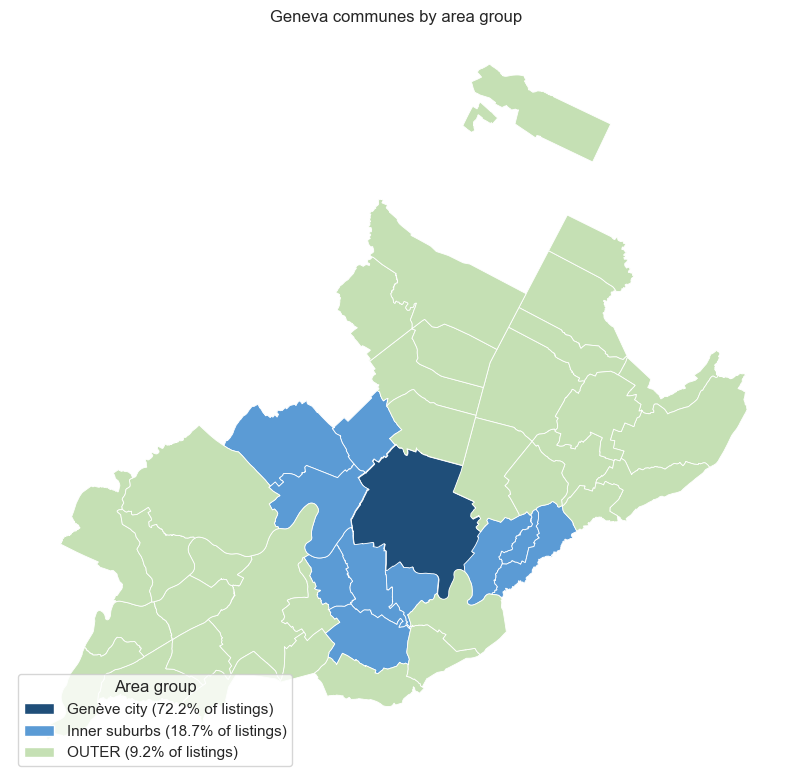

In [31]:
# Map A: 3 area classes
area_colors = {
    'Genève city': '#1f4e79',
    'Inner suburbs': '#5b9bd5',
    'OUTER': '#c5e0b4',
}

fig, ax = plt.subplots(figsize=(9, 8))

for area, color in area_colors.items():
    subset = map_df[map_df['area_group'] == area]
    subset.plot(ax=ax, color=color, edgecolor='white', linewidth=0.6)

# geopandas label= often does not show up, so I build the legend myself
legend_handles = [
    Patch(
        facecolor=area_colors[area],
        edgecolor='white',
        label=f'{area} ({class_share.loc[area]:.1f}% of listings)',
    )
    for area in ['Genève city', 'Inner suburbs', 'OUTER']
]

ax.set_title('Geneva communes by area group')
ax.set_axis_off()
ax.legend(handles=legend_handles, loc='lower left', frameon=True, title='Area group')
plt.tight_layout()
plt.show()

Deep blue is Genève city and it takes most of the listings. Light blue is the inner suburbs around it, green is OUTER. The legend shows the share of listings, not the share of land.

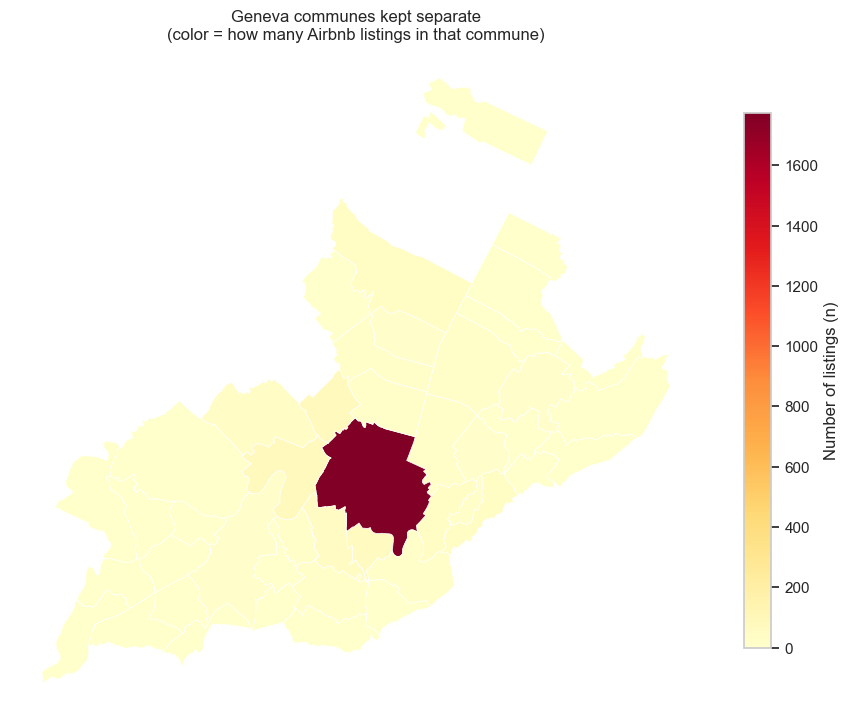

In [32]:
# Map B: all communes kept separate, colored by number of listings
fig, ax = plt.subplots(figsize=(9, 8))

map_df.plot(
    ax=ax,
    column='n',
    cmap='YlOrRd',
    edgecolor='white',
    linewidth=0.5,
    legend=True,
    legend_kwds={'label': 'Number of listings (n)', 'shrink': 0.7},
)

ax.set_title('Geneva communes kept separate\n(color = how many Airbnb listings in that commune)')
ax.set_axis_off()
plt.tight_layout()
plt.show()

Same map but every commune stays separate. Darker red means more listings. You basically see again that supply is concentrated in the city and a few nearby communes.

### Ridgeline of price by area group

This shows the full price distribution for each class, stacked. I use `price_plot` (capped at the 95th percentile) so a few extreme prices do not flatten everything.


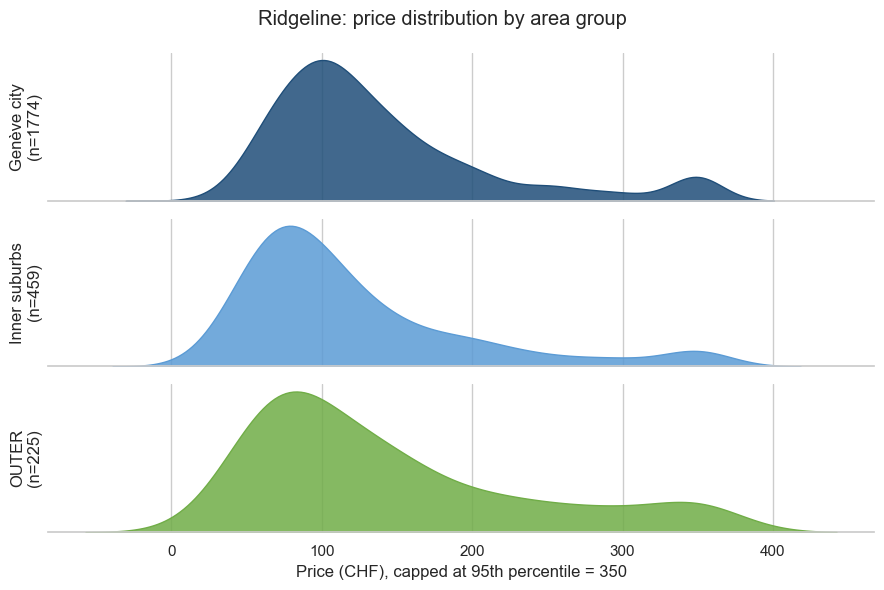

In [33]:
area_order = ['Genève city', 'Inner suburbs', 'OUTER']
ridge_colors = ['#1f4e79', '#5b9bd5', '#70ad47']

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(9, 6), sharex=True)

for ax, area, color in zip(axes, area_order, ridge_colors):
    subset = df.loc[df['area_group'] == area, 'price_plot']
    n = (df['area_group'] == area).sum()
    sns.kdeplot(subset, ax=ax, fill=True, color=color, alpha=0.85, linewidth=1)
    ax.set_ylabel(f'{area}\n(n={n})')
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes[-1].set_xlabel(f'Price (CHF), capped at 95th percentile = {price_cap:.0f}')
fig.suptitle('Ridgeline: price distribution by area group')
plt.tight_layout()
plt.show()

Prices overlap a lot across the three groups. Inner suburbs look a bit cheaper overall, but there is no totally different price world outside the city.

### Strip plot of review scores by area group

Only listings that already have a rating. Each point is one listing, so we can see if one class has more low scores or if they all sit high.


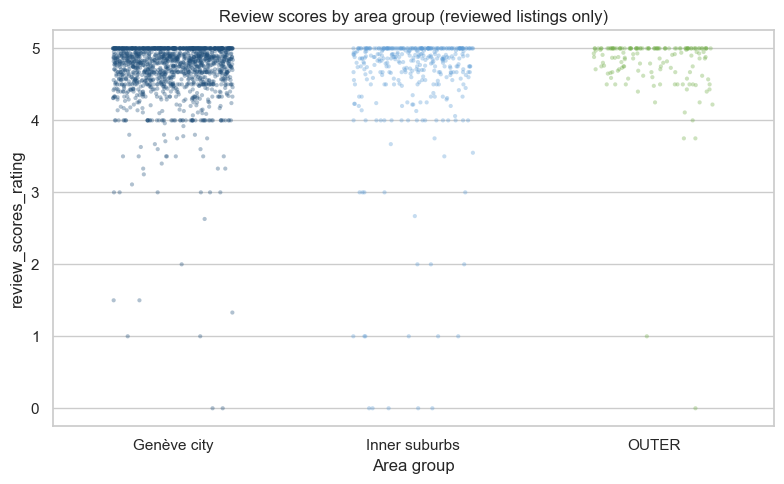

               count      mean  median
area_group                            
Genève city     1489  4.700437    4.81
Inner suburbs    365  4.582877    4.86
OUTER            157  4.770701    4.95


In [34]:
rated = df[df['review_scores_rating'].notna()].copy()

fig, ax = plt.subplots(figsize=(8, 5))
sns.stripplot(
    data=rated,
    x='area_group',
    y='review_scores_rating',
    order=area_order,
    hue='area_group',
    hue_order=area_order,
    palette=ridge_colors,
    alpha=0.35,
    size=3,
    jitter=0.25,
    legend=False,
    ax=ax,
)
ax.set_title('Review scores by area group (reviewed listings only)')
ax.set_xlabel('Area group')
ax.set_ylabel('review_scores_rating')
plt.tight_layout()
plt.show()

print(rated.groupby('area_group')['review_scores_rating'].agg(['count', 'mean', 'median']).reindex(area_order))

Most ratings sit very high in every group. There are some low scores in each class, so the story is more "generally good" than "one region is clearly better".

### Heatmap of top communes (n >= 20)

One table-like picture for the communes with enough data. Because price, reviews, rating, beds and amenities are on totally different scales, I color each column after scaling it from 0 to 1 inside that column only. Darker means higher inside that metric. The numbers written in the cells are the real values, so the colors do not confuse the reader.


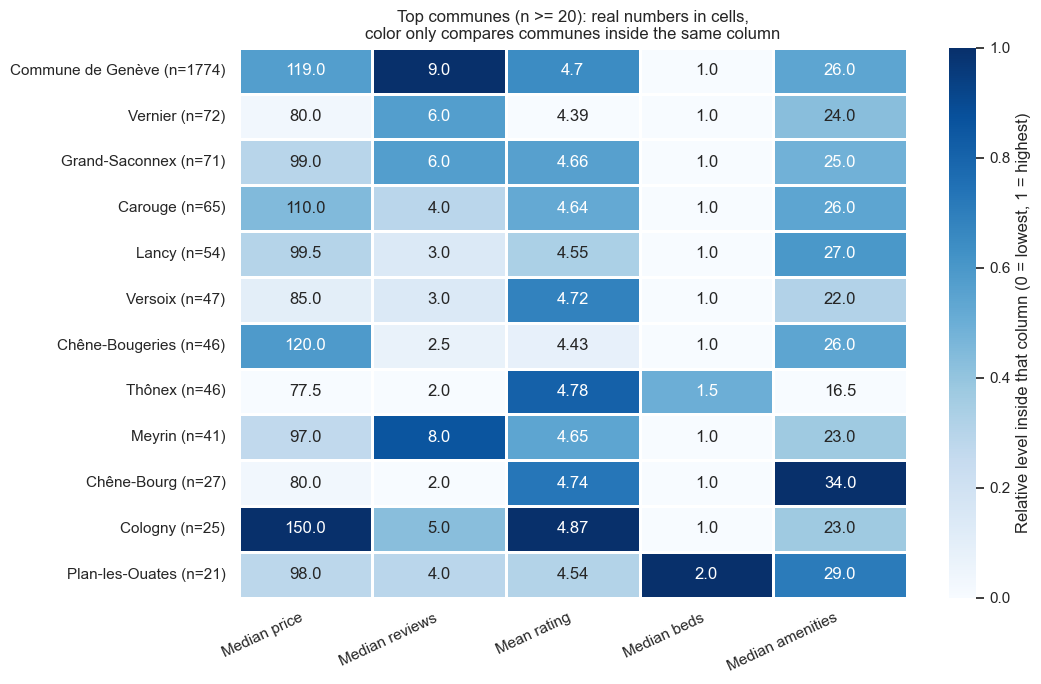

In [35]:
top_communes = stats_by_commune[stats_by_commune['n'] >= 20].copy()

heat_raw = top_communes[[
    'median_price',
    'median_reviews',
    'mean_rating_reviewed',
    'median_beds',
    'median_amenity_count',
]].rename(columns={
    'median_price': 'Median price',
    'median_reviews': 'Median reviews',
    'mean_rating_reviewed': 'Mean rating',
    'median_beds': 'Median beds',
    'median_amenity_count': 'Median amenities',
})

# add n into the row label so sample size stays visible
heat_raw.index = [
    f"{idx} (n={int(top_communes.loc[idx, 'n'])})"
    for idx in heat_raw.index
]

# color = column-wise 0-1 scale, annotation = real numbers
heat_color = heat_raw.apply(lambda col: (col - col.min()) / (col.max() - col.min() + 1e-9))

fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(
    heat_color,
    annot=heat_raw.round(2),
    fmt='',
    cmap='Blues',
    linewidths=0.8,
    linecolor='white',
    cbar_kws={'label': 'Relative level inside that column (0 = lowest, 1 = highest)'},
    ax=ax,
)
ax.set_title(
    'Top communes (n >= 20): real numbers in cells,\n'
    'color only compares communes inside the same column'
)
ax.set_xlabel('')
ax.set_ylabel('')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

Read the numbers in the cells, not only the color. Color is only relative inside each column. Useful to spot things like higher price in Cologny without mixing that with beds or ratings.

### Scatter: reviews vs price, colored by area group

Question behind this one: do more expensive places also get more reviews, and does that depend on the region? Again I use capped price for the x axis so the cloud is readable.


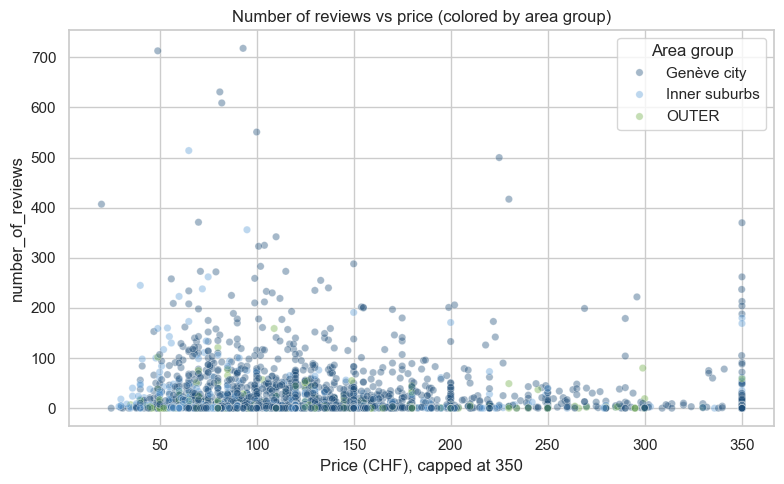

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='price_plot',
    y='number_of_reviews',
    hue='area_group',
    hue_order=area_order,
    palette=ridge_colors,
    alpha=0.4,
    s=28,
    ax=ax,
)
ax.set_title('Number of reviews vs price (colored by area group)')
ax.set_xlabel(f'Price (CHF), capped at {price_cap:.0f}')
ax.set_ylabel('number_of_reviews')
ax.legend(title='Area group')
plt.tight_layout()
plt.show()

No clear "expensive means tons of reviews" pattern. A lot of listings have few reviews at every price level, in every area.

### Host response time by region and price

First I check how response times are mixed inside each area group (shares, not raw counts). Then I flip the question to price: if the listing is more expensive, do we see more fast replies?


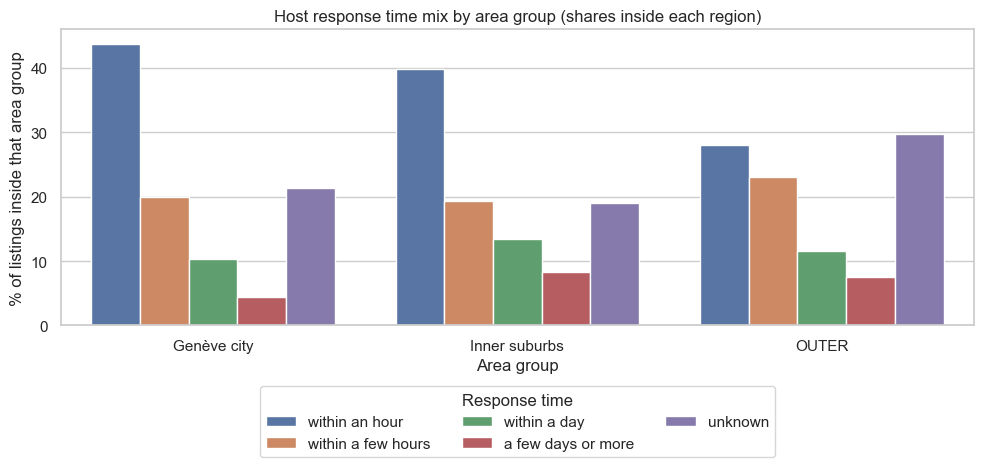

host_response_time_clean,within an hour,within a few hours,within a day,a few days or more,unknown
area_group,,,,,
Genève city,43.8,20.0,10.4,4.4,21.4
Inner suburbs,39.9,19.4,13.5,8.3,19.0
OUTER,28.0,23.1,11.6,7.6,29.8


In [37]:
# share of each response time inside each area group
resp_share = (
    df.groupby('area_group')['host_response_time_clean']
      .value_counts(normalize=True)
      .rename('share')
      .reset_index()
)
resp_share['share_pct'] = (resp_share['share'] * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=resp_share,
    x='area_group',
    y='share_pct',
    hue='host_response_time_clean',
    order=area_order,
    hue_order=response_order,
    ax=ax,
)
ax.set_title('Host response time mix by area group (shares inside each region)')
ax.set_xlabel('Area group')
ax.set_ylabel('% of listings inside that area group')
ax.legend(title='Response time', loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=True)
plt.tight_layout()
plt.show()

resp_share.pivot(index='area_group', columns='host_response_time_clean', values='share_pct').reindex(area_order)

The distribution looks fairly similar across groups, except OUTER which has more unknown values. I will now check if there is a difference in response time based on the price of the listing.

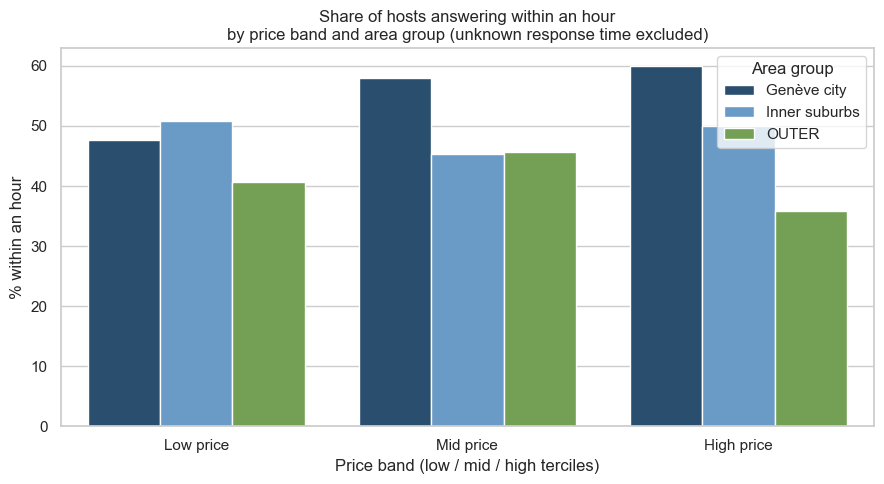

area_group,Genève city,Inner suburbs,OUTER
price_band,,,
Low price,47.6,50.8,40.7
Mid price,58.0,45.3,45.7
High price,60.0,50.0,35.9


In [38]:
# clearer question: among higher priced listings, is "within an hour" more common?
# Low / Mid / High = price terciles
df['price_band'] = pd.qcut(df['price'], q=3, labels=['Low price', 'Mid price', 'High price'])

# unknown is not really a speed, so I drop it for this specific question
known_resp = df[df['host_response_time_clean'] != 'unknown'].copy()
known_resp['is_fast'] = known_resp['host_response_time_clean'] == 'within an hour'

fast_by_price = (
    known_resp.groupby(['price_band', 'area_group'], observed=True)['is_fast']
      .mean()
      .mul(100)
      .round(1)
      .rename('pct_within_an_hour')
      .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=fast_by_price,
    x='price_band',
    y='pct_within_an_hour',
    hue='area_group',
    order=['Low price', 'Mid price', 'High price'],
    hue_order=area_order,
    palette=ridge_colors,
    ax=ax,
)
ax.set_title('Share of hosts answering within an hour\nby price band and area group (unknown response time excluded)')
ax.set_xlabel('Price band (low / mid / high terciles)')
ax.set_ylabel('% within an hour')
ax.legend(title='Area group')
plt.tight_layout()
plt.show()

fast_by_price.pivot(index='price_band', columns='area_group', values='pct_within_an_hour')

If higher price meant faster answers everywhere, all bars would rise from left to right. In Genève city it goes up a bit (more "within an hour" in the high price band). INNER is pretty flat, and OUTER even looks weaker on the expensive side. So there is no clean rule that expensive listings always get faster hosts.

### Short wrap up

The maps show the imbalance clearly: most listings are in Genève city. Prices and ratings overlap a lot across the three groups, with inner suburbs a bit cheaper. The heatmap is mainly useful for communes with enough data. Reviews vs price do not show a strong pattern. Response times look similar by region except OUTER has more unknowns, and higher price does not clearly mean faster replies.


## 4. Mapping

Simple map of the Airbnb rentals using latitude / longitude. I color the points by our 3 area groups so it matches the rest of the analysis.


In [39]:
# center the map on Geneva (OpenStreetMap tiles, no API key needed)
geneva_map = folium.Map(
    location=[df['latitude'].median(), df['longitude'].median()],
    zoom_start=11,
    tiles='OpenStreetMap',
)

map_colors = {
    'Genève city': '#1f4e79',
    'Inner suburbs': '#5b9bd5',
    'OUTER': '#70ad47',
}

# cluster points so the city does not become one giant mess
cluster = MarkerCluster().add_to(geneva_map)

for _, row in df.iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=2,
        color=map_colors.get(row['area_group'], 'gray'),
        fill=True,
        fill_opacity=0.6,
        popup=f"{row['neighbourhood_cleansed']}<br>{row['area_group']}<br>price: {row['price']}",
    ).add_to(cluster)

geneva_map

Most points sit in the city and around the lake. The inner suburbs form a ring next to Genève city, and OUTER is more spread out toward the edges of the canton. You can really see why Commune de Genève dominates the counts: that is where the dense cloud of listings is.

## 5. Word Cloud

I use `neighborhood_overview` and only the rows that actually have text (we left the blanks on purpose earlier).


overviews used: 1185
top words: [('quartier', 477), ('restaurants', 450), ('minutes', 412), ('geneva', 411), ('lake', 269), ('genève', 259), ('walk', 258), ('bars', 220), ('ville', 220), ('centre', 216), ('bus', 214), ('area', 194), ('away', 189), ('located', 183), ('neighborhood', 175)]


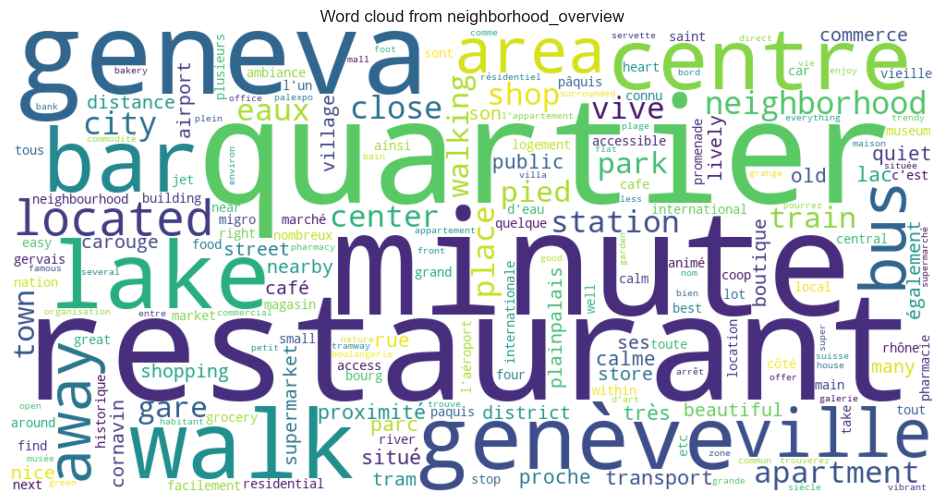

In [40]:
overviews = df['neighborhood_overview'].dropna().astype(str)
text = ' '.join(overviews).lower()

# keep words, drop very short tokens
words = re.findall(r"[a-zA-Zàâäéèêëïîôùûüç']{3,}", text)

# basic stopwords + a few travel filler words that add little meaning
stopwords = set(WordCloud().stopwords)
stopwords.update({
    'the', 'and', 'for', 'with', 'from', 'that', 'this', 'are', 'you', 'your',
    'can', 'all', 'also', 'very', 'just', 'will', 'one', 'deux', 'des', 'les',
    'une', 'dans', 'pour', 'par', 'sur', 'est', 'pas', 'plus', 'avec', 'qui',
    'que', 'aux', 'du', 'de', 'la', 'le', 'et', 'en', 'un', 'au', 'vous', 'nous',
    'min', 'mins',
})

clean_words = [w for w in words if w not in stopwords]
print('overviews used:', len(overviews))
print('top words:', Counter(clean_words).most_common(15))

wc = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    stopwords=stopwords,
    collocations=False,
).generate(' '.join(clean_words))

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word cloud from neighborhood_overview')
plt.show()

The big words are things like quartier, restaurants, geneva/genève, lake, walk, bars, centre. Hosts mostly sell the neighborhood as walkable and close to food / the lake / the city center.

# Part 2. Prediction

Multiple regression with outcome variable `price` (CHF).

## Model setup

The goal is to predict the listed price of a Geneva Airbnb in Swiss francs using multiple regression. I start with guest capacity and room type because they describe how many guests a listing can host and what kind of space it offers.

### Checking prices and candidate predictors

I read the CSV into `regression_df` so the data used in this section stays separate from `df` in Part 1. After converting `price` to a numeric column, I checked the most expensive listings because the maximum of CHF 25,000 was far above the 75th percentile of CHF 163. I also checked which candidate predictors had missing values before deciding what to include.

In [49]:
regression_df = pd.read_csv(Path("geneva_listings.csv"))

print("Rows and columns:", regression_df.shape)

Rows and columns: (2458, 75)


In [53]:
# Remove currency formatting so price can be used in the regression.
regression_df["price"] = (regression_df["price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float))

print(regression_df["price"].head())
print("Missing prices:", regression_df["price"].isna().sum())
print(regression_df["price"].describe())

0     89.0
1     60.0
2    165.0
3     80.0
4    147.0
Name: price, dtype: float64
Missing prices: 0
count     2458.000000
mean       174.024817
std        611.108033
min         20.000000
25%         82.000000
50%        114.500000
75%        163.000000
max      25000.000000
Name: price, dtype: float64


In [55]:
# Inspect 10 highest prices because a few extreme values may affect the fit.
listing_cols = ["id", 
                "name", 
                "room_type", 
                "accommodates", 
                "price"]

print("\n10 highest-priced listings")
print(regression_df.nlargest(10, "price")[listing_cols].to_string(index=False))


10 highest-priced listings
          id                                                              name       room_type  accommodates   price
7.659340e+17                Home in Bellevue · 5 bedrooms · 7 beds · 4.5 baths Entire home/apt            12 25000.0
5.090975e+07               Condo in Genève · ★4.33 · 1 bedroom · 1 shared bath    Private room             1  8577.0
7.340670e+17                  Villa in Cologny · 5 bedrooms · 5 beds · 5 baths Entire home/apt            10  8000.0
2.440767e+07 Rental unit in Genève · ★4.90 · 1 bedroom · 1 bed · 1 shared bath    Private room             1  6582.0
7.650190e+17                     Boat in Bellevue · 1 bedroom · 1 bed · 1 bath Entire home/apt             9  6500.0
7.614080e+17             Rental unit in Genève · 4 bedrooms · 4 beds · 4 baths Entire home/apt             8  5000.0
1.745476e+07        Rental unit in Genève · ★4.67 · 1 bedroom · 1 bed · 1 bath Entire home/apt             3  3000.0
1.849379e+07        Home in Collonge

The most expensive listing was a home in Bellevue that accommodated 12 guests and was listed at CHF 25,000. That was nearly three times the next-highest price of CHF 8,577. Two of the four most expensive listings were private rooms for one guest, so high prices appeared among both small and large listings.

The table gave me no clear reason to treat the CHF 25,000 price as a data-entry error, so I kept it in the baseline analysis. Once I found it in the training set, I refitted the same model without that one listing and used the same test set to see how much the coefficient for guest capacity and the prediction errors changed.

In [51]:
# Check missing values before choosing the predictors.
candidate_cols = ["accommodates",
                  "bedrooms",
                  "beds",
                  "room_type",
                  "neighbourhood_cleansed"]

print("\nMissing values in candidate predictors")
print(regression_df[candidate_cols].isna().sum())


Missing values in candidate predictors
accommodates                0
bedrooms                  842
beds                       35
room_type                   0
neighbourhood_cleansed      0
dtype: int64


### Fitting the baseline regression

I started with `accommodates` and `room_type` because both are easy to interpret and had no missing values. I left out `bedrooms` because 842 listings were missing that information. I used guest capacity as the model’s measure of listing size and left bed count out of this comparison. I used 80% of the listings to fit the model and set aside 20% to evaluate its predictions. Room type was treated as categorical, with Entire home/apt as the reference category.

In [56]:
regression_data = regression_df[["price", "accommodates", "room_type"]].copy()

# Hold out 20% of the listings to evaluate prediction errors.
regression_train, regression_test = train_test_split(regression_data, 
                                                     test_size=0.20, 
                                                     random_state=42)

# Check where the highest-priced listing fell before measuring its influence.
highest_price_index = regression_data["price"].idxmax()
highest_price_split = ("training" if highest_price_index in regression_train.index else "test")

print(f"Highest-priced listing is in the {highest_price_split} set.")

Highest-priced listing is in the training set.


In [59]:
# Keep all training listings in the baseline model.
price_formula = "price ~ accommodates + C(room_type)"
baseline_regression = smf.ols(price_formula, data=regression_train).fit()

print("\nBaseline multiple regression")
print(baseline_regression.summary())


Baseline multiple regression
                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.074
Model:                            OLS   Adj. R-squared:                  0.072
Method:                 Least Squares   F-statistic:                     39.35
Date:                Thu, 26 Nov 2026   Prob (F-statistic):           9.84e-32
Time:                        20:09:34   Log-Likelihood:                -15451.
No. Observations:                1966   AIC:                         3.091e+04
Df Residuals:                    1961   BIC:                         3.094e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------

The baseline model explained 7.4% of the variation in listed prices in the training data. Holding room type constant, the model estimated a CHF 120.44 higher price for each additional guest the listing could accommodate.

The residuals were strongly right-skewed, and the CHF 25,000 listing was in the training set. Since that listing accommodated 12 guests, I wanted to see how much it influenced the estimated relationship between capacity and price. I kept the same predictors and refitted the model without that one listing to check how much the coefficient changed.

### Checking the influence of the highest price

I refitted the baseline model without the CHF 25,000 listing and evaluated both fits on the same test set.

In [77]:
# Refit the original-price model after dropping the highest training price.
train_without_highest = regression_train.drop(index=highest_price_index)
regression_without_highest = smf.ols(price_formula, 
                                     data=train_without_highest).fit()

# Use the same test set for both original-price models.
regression_comparison = []
actual_prices = regression_test["price"]

for label, fitted_model in [("Baseline", baseline_regression),
                            ("Without CHF 25,000 training listing", 
                             regression_without_highest),]:
    predicted_prices = fitted_model.predict(regression_test)
    regression_comparison.append({"Model": label,
                                  "Test MAE": mean_absolute_error(actual_prices, predicted_prices),
                                  "Test RMSE": mean_squared_error(actual_prices, predicted_prices) ** 0.5,
                                  "Accommodates coefficient": fitted_model.params["accommodates"]})

print("\nEffect of the highest-priced training listing")
print(pd.DataFrame(regression_comparison).round(2).to_string(index=False))


Effect of the highest-priced training listing
                              Model  Test MAE  Test RMSE  Accommodates coefficient
                           Baseline    132.96     427.40                    120.44
Without CHF 25,000 training listing     94.57     413.51                     66.56


Removing the CHF 25,000 listing from the training set lowered the estimated price difference per additional guest from CHF 120.44 to CHF 66.56, holding room type constant. On the same test set, MAE fell from CHF 132.96 to CHF 94.57, while RMSE fell from CHF 427.40 to CHF 413.51. The change in the coefficient shows how sensitive the original-price model was to this one listing. The smaller drop in RMSE suggests that large prediction errors remained.

For the next model, I kept all the training listings and applied a log transformation to price. I wanted to see whether compressing the large price differences would improve predictions while keeping the highest-priced listing in the analysis.

In [78]:
# Fit the log-price model using all training listings.
log_price_formula = "np.log(price) ~ accommodates + C(room_type)"
log_regression = smf.ols(log_price_formula, data=regression_train).fit()

log_predictions_chf = np.exp(log_regression.predict(regression_test))
log_result = {"Model": "Log-price regression",
              "Test MAE": mean_absolute_error(actual_prices, log_predictions_chf),
              "Test RMSE": mean_squared_error(actual_prices, log_predictions_chf) ** 0.5}

# Build a fresh comparison with the two original-price models and the log model.
comparison_table = pd.DataFrame(regression_comparison[:2] + [log_result])
comparison_cols = ["Model", "Test MAE", "Test RMSE"]

print("\nTest performance comparison (CHF)")
print(comparison_table[comparison_cols].round(2).to_string(index=False))


Test performance comparison (CHF)
                              Model  Test MAE  Test RMSE
                           Baseline    132.96     427.40
Without CHF 25,000 training listing     94.57     413.51
               Log-price regression     77.16     414.98


The log-price model had the lowest test MAE at CHF 77.16. Compared with the original-price model fitted on the same training listings, including the CHF 25,000 listing, MAE was about 42% lower. Its RMSE of CHF 414.98 was close to the CHF 413.51 achieved by the model fitted without the highest-priced listing. The log transformation helped most with average absolute error, while large prediction errors remained.

I used the log-price model for the next comparison because it had the lowest MAE. I then tested whether adding the three area groups from Part 1 improved predictions beyond guest capacity and room type. I used five-fold cross-validation within the training set to make that decision.

### Testing whether area helps predict price

Some communes had only one or two listings in the training set, so I used the three broader area groups defined in Part 1. I compared the log-price models with and without area group using the same five validation folds within the training data. This allowed me to evaluate whether location added predictive value while keeping guest capacity and room type in both models.

In [68]:
# Check how many training listings are available in each commune.
train_areas = regression_df.loc[regression_train.index, "neighbourhood_cleansed"]

print("Training listings by area")
print(train_areas.value_counts().to_string())

Training listings by area
neighbourhood_cleansed
Commune de Genève     1419
Grand-Saconnex          61
Carouge                 54
Vernier                 51
Lancy                   41
Chêne-Bougeries         39
Versoix                 37
Thônex                  37
Meyrin                  31
Chêne-Bourg             22
Cologny                 19
Plan-les-Ouates         18
Pregny-Chambésy         15
Veyrier                 14
Onex                    13
Bellevue                13
Collonge-Bellerive      11
Genthod                  8
Bernex                   8
Vandoeuvres              6
Meinier                  5
Anières                  5
Bardonnex                4
Troinex                  4
Corsier                  4
Hermance                 4
Collex-Bossy             3
Laconnex                 2
Dardagny                 2
Soral                    2
Confignon                2
Puplinge                 2
Satigny                  2
Presinge                 2
Céligny                  2
Jussy 

Commune de Genève accounted for 1,419 of the 1,966 training listings, or about 72%. The next-largest commune, Grand-Saconnex, had 61 listings, and several communes had only one or two. With so few listings in some communes, a separate price estimate for each commune could depend heavily on individual listings.

I used the three broader groups defined in Part 1: Genève city, Inner suburbs, and OUTER. This gave me a way to test whether location improved the model while keeping the comparison simple.

In [70]:
# Reuse the area group definitions from Part 1.
regression_inner_suburbs = ["Carouge", 
                            "Lancy", 
                            "Vernier", 
                            "Grand-Saconnex", 
                            "Meyrin",
                            "Onex", 
                            "Chêne-Bourg", 
                            "Chêne-Bougeries", 
                            "Thônex", 
                            "Plan-les-Ouates"]

regression_cv_data = regression_train.copy()
regression_cv_data["area_group"] = "OUTER"
regression_cv_data.loc[train_areas.isin(regression_inner_suburbs), "area_group"] = "Inner suburbs"
regression_cv_data.loc[train_areas.eq("Commune de Genève"), "area_group"] = "Genève city"

In [71]:
# Retain the same category labels across validation folds.
regression_cv_data["room_type"] = regression_cv_data["room_type"].astype("category")
regression_cv_data["area_group"] = regression_cv_data["area_group"].astype("category")

regression_formulas = {"Without area group": log_price_formula,
                       "With area group": log_price_formula + " + C(area_group)"}

In [79]:
# Compare both specifications on the same five folds.
regression_cv = KFold(n_splits=5, shuffle=True, random_state=42)
regression_cv_results = []

for train_positions, val_positions in regression_cv.split(regression_cv_data):
    fold_train = regression_cv_data.iloc[train_positions]
    fold_val = regression_cv_data.iloc[val_positions]

    for label, formula in regression_formulas.items():
        fold_model = smf.ols(formula, data=fold_train).fit()
        fold_predictions_chf = np.exp(fold_model.predict(fold_val))
        regression_cv_results.append({
            "Model": label,
            "MAE": mean_absolute_error(fold_val["price"], fold_predictions_chf),
            "RMSE": mean_squared_error(fold_val["price"], fold_predictions_chf) ** 0.5,})

print("\nAverage 5-fold validation errors")
print(pd.DataFrame(regression_cv_results).groupby("Model").mean().round(2))


Average 5-fold validation errors
                      MAE   RMSE
Model                           
With area group     82.85  502.9
Without area group  82.81  503.0


### Did area group improve predictions?

Across the same five validation folds, adding area group increased average MAE from CHF 82.81 to CHF 82.85 and reduced average RMSE from CHF 503.00 to CHF 502.90. The changes were only a few cents, so adding the three area groups offered little practical improvement in this comparison. I kept guest capacity and room type in the final log-price model.

In [80]:
print("\nSelected log-price regression summary")
print(log_regression.summary())


Selected log-price regression summary
                            OLS Regression Results                            
Dep. Variable:          np.log(price)   R-squared:                       0.368
Model:                            OLS   Adj. R-squared:                  0.367
Method:                 Least Squares   F-statistic:                     285.2
Date:                Thu, 26 Nov 2026   Prob (F-statistic):          1.95e-193
Time:                        20:42:02   Log-Likelihood:                -1404.5
No. Observations:                1966   AIC:                             2819.
Df Residuals:                    1961   BIC:                             2847.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------

### Final regression equation

The OLS summary above reports the coefficients for the final log-price model. Using those estimates, the fitted equation is:

$$
\widehat{\ln(\text{price})}
= 4.3691 + 0.1943(\text{accommodates})
+ 0.5988 I_{\text{Hotel}}
- 0.2753 I_{\text{Private}}
- 0.7717 I_{\text{Shared}}
$$

Entire home/apt is the reference category. Each room-type indicator is 1 for that room type and 0 otherwise. Holding room type constant, capacity for one additional guest is associated with a predicted price about 21.4% higher, calculated as \(100(e^{0.1943}-1)\).

At the same guest capacity, the model predicts prices about 24.1% lower for private rooms and 53.8% lower for shared rooms than for entire homes or apartments. The estimated price for hotel rooms is about 82.0% higher, though that estimate has a wider confidence interval than the estimates for the other room types.

### Our narrative

We started with guest capacity and room type because they describe two basic features of each listing and had no missing values. We left out bedrooms because 842 listings were missing that information and used guest capacity as our measure of size. We also tested whether adding the three area groups from Part 1 improved the log-price model. Across the same five validation folds, adding area group changed MAE from CHF 82.81 to CHF 82.85, so we kept guest capacity and room type in the final model.

We used an 80/20 train-test split and evaluated all three models on the same 492 test listings. The CHF 25,000 listing was in the training set. When we removed it from the original-price model, the estimated price difference per additional guest fell from CHF 120.44 to CHF 66.56. That change showed how sensitive the original-price fit was to one listing. We then kept all the training listings, fitted a model using log price, and converted the predictions back to CHF to compare MAE and RMSE.

The final model explained 36.8% of the variation in log prices in the training data. On the test set, it had an MAE of CHF 77.16, about 42% lower than the CHF 132.96 from the original-price model fitted on the same training listings. RMSE decreased from CHF 427.40 to CHF 414.98. The log transformation reduced the average absolute error substantially, while larger misses still had a noticeable effect on RMSE.

## Part I. k-NN

Goal: use k-nearest neighbors with numerical predictors to predict whether a listing has a particular amenity (or a small set of amenities).

How the model works: each listing is a point based on features like price, bedrooms, location, and room type. For a new listing, KNN finds the k most similar training listings and takes a majority vote on full laundry. "Similar" means close in distance after we scale the features.


### Exploring amenities first

Same idea as the transformer part: work on a separate frame `knn_df = df.copy()` so KNN flags and dummies do not clutter the main `df`.

Before picking y, I look at how common amenities are. Wifi and Kitchen show up almost everywhere, so predicting those would be too easy and not a useful story. Left plot = top 25 overall. Right plot = amenities in roughly the 20% to 55% range, which are usually better KNN targets.


In [ ]:
# separate frame for KNN (leave main df alone)
knn_df = df.copy()

# parse amenities into lists (needed for the count + later 0/1 flags)
def parse_amenities(x):
    try:
        return ast.literal_eval(x) if pd.notna(x) else []
    except (ValueError, SyntaxError):
        return []

knn_df['amenities_list'] = knn_df['amenities'].apply(parse_amenities)

# full frequency table
amenity_counts = Counter()
for lst in knn_df['amenities_list']:
    amenity_counts.update(lst)

amenity_freq = (
    pd.Series(dict(amenity_counts), name='n')
      .to_frame()
      .assign(pct=lambda d: (d['n'] / len(knn_df) * 100).round(1))
      .sort_values('pct', ascending=False)
)

# 1) top 25 overall (context)
top25 = amenity_freq.head(25).sort_values('pct')

fig, axes = plt.subplots(1, 2, figsize=(14, 9))

axes[0].barh(top25.index, top25['pct'], color='#5b9bd5')
axes[0].set_xlabel('% of listings')
axes[0].set_title('Top 25 most common amenities')
for i, (amenity, row) in enumerate(top25.iterrows()):
    axes[0].text(row['pct'] + 0.5, i, f"{row['pct']}%", va='center', fontsize=8)

# 2) better KNN candidates: not too rare, not almost everyone
# roughly the "20% to 55%" zone
candidates = amenity_freq[(amenity_freq['pct'] >= 20) & (amenity_freq['pct'] <= 55)].sort_values('pct')

axes[1].barh(candidates.index, candidates['pct'], color='#70ad47')
axes[1].set_xlabel('% of listings')
axes[1].set_title('Better KNN targets (20% to 55%)\nmore balanced yes/no split')
axes[1].axvline(50, color='gray', linestyle='--', linewidth=1, alpha=0.7)
for i, (amenity, row) in enumerate(candidates.iterrows()):
    axes[1].text(row['pct'] + 0.4, i, f"{row['pct']}%", va='center', fontsize=8)

plt.tight_layout()
plt.show()

print('Possible KNN outcomes (20% to 55%):')
print(candidates.sort_values('pct', ascending=False)[['n', 'pct']].head(25))


### Decision: what we predict, and which 0/1 columns we build

We thought about predicting one amenity (parking, workspace, elevator, etc.) or a small set. A set tells a clearer story for the assignment: Washer + Dryer as "full laundry," meaning the place is set up for a longer or more practical stay, not only a short tourist stop.

We also decided not to create 0/1 columns for every amenity (or even the top 20). Our predictors will be numeric listing features anyway, so extra amenity flags would just clutter the dataframe. We only build `has_washer` and `has_dryer`, then combine them into the outcome `has_full_laundry`.


In [ ]:
# only Washer and Dryer -> then the combined outcome (on knn_df only)
knn_df['has_washer'] = knn_df['amenities_list'].apply(lambda lst: int('Washer' in lst))
knn_df['has_dryer'] = knn_df['amenities_list'].apply(lambda lst: int('Dryer' in lst))

knn_df['has_full_laundry'] = (
    (knn_df['has_washer'] == 1) & (knn_df['has_dryer'] == 1)
).astype(int)

print('share washer:', round(knn_df['has_washer'].mean(), 3))
print('share dryer:', round(knn_df['has_dryer'].mean(), 3))
print(knn_df['has_full_laundry'].value_counts())
print('share full laundry (both):', round(knn_df['has_full_laundry'].mean(), 3))


About 19% of listings have both, so a naive model that always says "no" is already pretty strong. That matters later when we compare KNN to the baseline.


### Predictors and train/test split

All of this stays on `knn_df` (then a dropna modeling subset). I only use numerical predictors. I am not putting other amenity yes/no flags in X, because then we would partly predict laundry from "how the host filled the amenity list," which feels circular. Rows with missing values in these columns are dropped for this model.

Why each feature:
- `price`: more complete / higher-end places are often more equipped, so maybe more likely to have full laundry
- `accommodates`, `bedrooms`, `beds`: bigger places feel more like an apartment for a real stay than a tiny room, so laundry makes more sense there
- `bathrooms`: same idea, a bit more of a full-home signal
- `number_of_reviews`: more established listings might be set up differently than brand new ones; also a general activity signal
- `latitude`, `longitude`: location in Geneva (city vs outer) might change what kind of housing it is, and that can link to laundry
- `amenity_count`: overall how loaded the listing is; places that list lots of stuff may also list washer+dryer (related to amenities, but still one number, not the target itself)
- `minimum_nights`: if the host wants longer stays, full laundry is a more natural offer
- `room_type` (encoded): entire home vs private room is a strong laundry story. A whole apartment is much more likely to have washer+dryer than a single private room. `property_type` is related but has about 40 messy levels, so I use `room_type` instead (only a few clean categories)

I keep this list fairly small on purpose. KNN gets weird when you throw too many columns at it, especially if some are noisy or half empty.

Train/test split (80/20) and why we stratify

I use an 80/20 split (`test_size=0.20`) so most rows train the model and we still hold out a clean test set. More important here is `stratify=y`.

Stratify means: keep the same class mix in train and in test. Full laundry is only about 19% of listings. Without stratify, a random split can accidentally put say 12% laundry in train and 25% in test (or the reverse). Then the model trains on the wrong sense of how rare laundry is, and the test score jumps around for luck.

With `stratify=y`, both sides stay about 19% yes / 81% no. That matters a lot for KNN because the prediction is just neighborhood voting. If the rare class is uneven across the split, the neighbors and the held-out labels are not describing the same Geneva reality.


In [ ]:
# room_type -> numeric dummies on knn_df (drop_first so we do not duplicate info)
room_dummies = pd.get_dummies(knn_df['room_type'], prefix='room', drop_first=True)
for col in room_dummies.columns:
    knn_df[col] = room_dummies[col].astype(int)

feature_cols = [
    'price',
    'accommodates',
    'bedrooms',
    'beds',
    'bathrooms',
    'number_of_reviews',
    'latitude',
    'longitude',
    'amenity_count',
    'minimum_nights',
] + list(room_dummies.columns)

print('room_type dummies added:', list(room_dummies.columns))

# modeling subset: drop rows missing any predictor / outcome
knn_model_df = knn_df[feature_cols + ['has_full_laundry']].dropna().copy()

X = knn_model_df[feature_cols]
y = knn_model_df['has_full_laundry']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print('rows used:', len(knn_model_df))
print('train:', X_train.shape[0], '| test:', X_test.shape[0])
print('train positive rate:', round(y_train.mean(), 3))

### Choosing k (and a few modeling choices)

I try several odd values of k with 5-fold stratified cross-validation on the training set. Odd k avoids tied votes when classes are even in a neighborhood.

StandardScaler

Price is in the hundreds, bedrooms are 1-5, lat/long are tiny decimals. KNN uses distance, so without scaling price would dominate everything and "nearest neighbor" would mostly mean "similar price." `StandardScaler` puts each feature on a comparable scale (mean 0, sd 1) inside the pipeline, so bedrooms and location can actually matter. Scaling only fits on training folds / train data, then transforms. We do not leak test information.

Distance metric: Euclidean

sklearn's default is Minkowski with p=2, which is Euclidean distance (straight-line distance in the scaled feature space). That fits our setup: mostly continuous numeric features plus a few 0/1 room-type dummies, all scaled. Alternatives exist (Manhattan = sum of absolute differences, sometimes a bit more robust to outliers; cosine = angle between vectors, more for text). For "how similar is this Geneva listing?" after scaling, Euclidean is the natural default, so we keep it and justify it rather than switch for no reason. We also use `weights='distance'` so closer neighbors vote louder than far ones inside the same k.

Why F1 (not accuracy) to pick k

Accuracy asks "how often was the label right?" With about 19% laundry, a dumb model that always says "no" is already about 81% accurate and useless. F1 balances precision (of predicted laundry, how many really have it) and recall (of real laundry listings, how many we caught). So when we loop over k, we select the best CV F1 for the positive class, but only among k >= 3. k = 1 often wins raw F1, yet it is basically "copy one neighbor" and overfits easily, so we show it for reference and do not use it as the final model. We still report accuracy and the confusion matrix. F1 is the selection rule so we do not reward "always no."


In [ ]:
# k=1 is allowed by the algorithm, but we do not use it as the final model:
# one neighbor overfits and is unstable. We evaluate k=1 for reference,
# then pick the best F1 among k >= 3.
ks_candidate = [3, 5, 7, 9, 11, 15, 21, 31]
ks = [1] + ks_candidate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_f1 = {}
cv_acc = {}

for k in ks:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k, weights='distance')),
    ])
    f1_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1')
    acc_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
    cv_f1[k] = f1_scores.mean()
    cv_acc[k] = acc_scores.mean()
    note = '  (reference only)' if k == 1 else ''
    print(f'k={k:>2} | CV F1 = {f1_scores.mean():.3f} | CV accuracy = {acc_scores.mean():.3f}{note}')

best_k = max(ks_candidate, key=lambda k: cv_f1[k])
print('best k among k>=3 (by F1):', best_k)
print('k=1 F1 for reference:', round(cv_f1[1], 3))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    list(cv_f1.keys()), list(cv_f1.values()),
    marker='o', markersize=8, linewidth=2.2, color='#2a6f97',
    label='CV F1 (laundry = yes)',
)
ax.plot(
    list(cv_acc.keys()), list(cv_acc.values()),
    marker='s', markersize=7, linewidth=2.2, color='#94a3b8',
    label='CV accuracy',
)
ax.axvline(best_k, color='#c1121f', linestyle='--', linewidth=1.4, alpha=0.85)
ax.scatter([best_k], [cv_f1[best_k]], s=120, color='#c1121f', zorder=5,
           label=f'chosen k = {best_k} (best F1, k>=3)')
ax.scatter([1], [cv_f1[1]], s=80, facecolors='none', edgecolors='#64748b',
           linewidths=1.5, zorder=5, label='k=1 (shown, not used)')
ax.annotate(
    f'k={best_k}\nF1={cv_f1[best_k]:.3f}',
    xy=(best_k, cv_f1[best_k]),
    xytext=(best_k + 4, cv_f1[best_k] + 0.05),
    fontsize=10, color='#c1121f',
    arrowprops=dict(arrowstyle='->', color='#c1121f', lw=1.2),
)
ax.set_xlabel('Number of neighbors (k)', fontsize=11)
ax.set_ylabel('Cross-validation score', fontsize=11)
ax.set_title('Choosing k for KNN (stratified 5-fold CV)', fontsize=13, pad=10)
ax.set_xticks(ks)
ax.set_ylim(0, 1)
ax.legend(frameon=True, fancybox=False, framealpha=0.95, loc='center right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()


### What best k means here (and why we skip k = 1)

k = 1 is allowed. sklearn will run it, and raw CV F1 is often highest there. We still do not use it as the final model.

Why not: with k = 1 the prediction is just "copy the single closest listing." One odd neighbor (weird price, outlier location, mislabeled amenities) flips the call. That is classic overfitting: great on nearby training points, shaky on new listings. For a project write-up, "we used 1 nearest neighbor" also sounds more like a lookup than a stable classifier.

So the rule is: still plot and report k = 1 for honesty, but choose the best F1 among k >= 3. In our CV that is k = 3: still local enough to catch some laundry signal, but a small vote instead of a single copy.

Tiny example. New 2-bedroom entire apartment in Carouge. With k = 1 we copy whatever laundry label the single closest training listing has. With k = 3 we look at the three closest places and take a distance-weighted vote. If two of three have laundry, we lean yes; one weird neighbor cannot decide alone. With k = 31 the vote gets flooded by Geneva's majority "no laundry," so we mostly predict no.

As k grows, accuracy tends to rise toward the "always no" baseline while laundry F1 falls. That is why we still select with F1, just not at the unstable extreme of k = 1.


### Fit final model and assess (including naive benchmark)


In [ ]:
knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=best_k, weights='distance')),
])
knn_model.fit(X_train, y_train)
y_pred = knn_model.predict(X_test)

# naive benchmark: always predict the majority class from training
naive_label = int(y_train.mode()[0])
y_naive = np.full_like(y_test, fill_value=naive_label)

knn_acc = accuracy_score(y_test, y_pred)
naive_acc = accuracy_score(y_test, y_naive)
cm = confusion_matrix(y_test, y_pred)

print('Chosen k:', best_k)
print('KNN test accuracy:  ', round(knn_acc, 3))
print('Naive test accuracy:', round(naive_acc, 3))
print('Naive always predicts:', naive_label)
print('\nConfusion matrix (rows=true, cols=pred):')
print(cm)
print('\nClassification report:')
print(classification_report(y_test, y_pred, digits=3))

fig, ax = plt.subplots(figsize=(5.2, 4.4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Pred: no laundry', 'Pred: laundry'],
    yticklabels=['True: no laundry', 'True: laundry'],
    cbar=False, linewidths=1.2, linecolor='white',
    annot_kws={'size': 14, 'weight': 'bold'},
    ax=ax,
)
ax.set_title(f'KNN test confusion matrix (k={best_k})', fontsize=12, pad=10)
plt.tight_layout()
plt.show()


### How to read the test results

Did accuracy go up with k? Yes. On CV, accuracy rises with k (about 0.75 at k=1, about 0.78 at k=3, about 0.81 for large k), while laundry F1 falls. That matches the plot. Large-k accuracy is basically chasing the naive "always no" rate.

With our chosen k=3, test accuracy = 0.78 means: out of every 100 held-out Geneva listings, KNN gets laundry yes/no right for about 78 of them. The naive "always no" baseline is 0.805, so on raw accuracy KNN still loses to the dummy rule. Moving from k=1 to k=3 did raise test accuracy (roughly 0.73 to 0.78), same pattern as CV, but we are still below naive. In the matrix: of 96 true laundry listings we catch 28 (recall about 0.29); when we predict laundry we are right 28 out of 68 times (precision about 0.41). Class 0 looks fine; class 1 is the hard part. Numeric listing features alone are only a weak signal for Washer+Dryer.

### Narrative for this part (assignment write-up)

We chose Washer + Dryer as the outcome ("full laundry") because those amenities are uncommon enough to be interesting (about 19% of Geneva listings have both), and together they tell a clear story about places set up for a longer stay. For predictors we stuck to numerical listing features: price, size (accommodates, bedrooms, beds, bathrooms), reviews, lat/long, amenity count, minimum nights, and room-type dummies. We avoided other amenity flags in X so we were not basically predicting laundry from the rest of the amenity checklist. We dropped rows with missing values in these columns for this model only, used an 80/20 stratified split so the laundry rate stayed honest in train and test, and scaled features with StandardScaler inside a pipeline so Euclidean distance was not dominated by price.

To pick k we ran stratified 5-fold CV over odd values, scored F1 for the laundry class (accuracy alone rewards "always no"), and selected the best F1 among k >= 3. k=1 had a slightly higher F1 but we skipped it as too unstable (copying one neighbor). That left k=3. On the held-out test set, KNN accuracy is 0.78 versus 0.805 for a naive majority-class baseline. The confusion matrix shows we only catch about 29% of true laundry listings, with precision around 0.41 when we predict yes. When the model says laundry, it is right about 41% of the time, which is above the 19% base rate (a blind guess would land near 19%). That is only a modest lift, and we still miss most true laundry listings. Numeric features alone do not strongly separate Washer+Dryer. Reporting accuracy without the naive benchmark and class-1 metrics would overstate how useful the model is.


## Part II. Classification tree (`host_response_time`)

The goal is to predict a Geneva Airbnb host’s response-time category using a classification tree. The tree splits listings into smaller groups using listing and host characteristics.

### Checking the response-time categories

I first counted how many listings fell into each response-time category and how many had missing labels. This helped me decide which listings could be used for training and whether the most common category could dominate the results.

In [81]:
# Load a separate dataframe for the classification tree.
tree_raw_df = pd.read_csv("geneva_listings.csv")
response_time = tree_raw_df["host_response_time"]

print("Host response time counts")
print(response_time.value_counts(dropna=False))
print("\nMissing response times:", response_time.isna().sum())

Host response time counts
host_response_time
within an hour        1023
NaN                    534
within a few hours     496
within a day           272
a few days or more     133
Name: count, dtype: int64

Missing response times: 534


### Preparing the data for the tree

Response time was missing for 534 listings. I used the 1,924 listings with a recorded response time so the tree could learn to distinguish among the four observed categories. I chose guest capacity and room type to describe the listing, review count to reflect past guest activity, and Superhost status and listing count to describe the host. Before fitting the tree, I checked how many values were missing in these predictors.

In [83]:
tree_target_col = "host_response_time"
tree_feature_cols = ["accommodates",
                     "room_type",
                     "number_of_reviews",
                     "host_is_superhost",
                     "host_listings_count"]

# Keep listings with a recorded response-time category.
tree_df = tree_raw_df.loc[tree_raw_df[tree_target_col].notna(),
    tree_feature_cols + [tree_target_col]].copy()

print("Listings available for classification:", len(tree_df))
print("\nResponse time proportions (%)")
print(tree_df[tree_target_col].value_counts(normalize=True).mul(100).round(1))

print("\nMissing values in candidate predictors")
print(tree_df[tree_feature_cols].isna().sum())

Listings available for classification: 1924

Response time proportions (%)
host_response_time
within an hour        53.2
within a few hours    25.8
within a day          14.1
a few days or more     6.9
Name: proportion, dtype: float64

Missing values in candidate predictors
accommodates           0
room_type              0
number_of_reviews      0
host_is_superhost      5
host_listings_count    0
dtype: int64


More than half of the listings had a response time within an hour (53.2%), while only 6.9% were in the slowest category. A model could therefore get a reasonable overall accuracy by predicting the most common response every time. I used balanced accuracy to compare tree depths because it gives each response category equal weight.

Superhost status was missing for five listings. I kept those listings and coded their status as `unknown` so they could still be included in the analysis.

### Choosing the tree depth

I used 80% of the listings for training and set aside 20% for the final test. I used a stratified split to keep the response-time proportions similar across the two sets. Within the training set, I compared tree depths using the same five stratified folds and selected the depth with the highest mean balanced accuracy.

In [87]:
# Keep the five listings with missing Superhost status.
tree_df["host_is_superhost"] = tree_df["host_is_superhost"].fillna("unknown")

tree_X = tree_df[tree_feature_cols]
tree_y = tree_df[tree_target_col]

# Preserve the response-time proportions in the training and test sets.
tree_X_train, tree_X_test, tree_y_train, tree_y_test = train_test_split(tree_X,
                                                                        tree_y,
                                                                        test_size=0.20,
                                                                        random_state=42,
                                                                        stratify=tree_y,)

# Encode categorical predictors separately within each training fold.
tree_preprocess = ColumnTransformer([("categories", 
                                      OneHotEncoder(handle_unknown="ignore"),
                                      ["room_type", "host_is_superhost"])],
                                    remainder="passthrough")

tree_pipeline = Pipeline([("preprocess",tree_preprocess),
                          ("tree", DecisionTreeClassifier(random_state=42))])

# Compare tree sizes with balanced accuracy on the training data.
tree_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tree_search = GridSearchCV(tree_pipeline,
                           param_grid={"tree__max_depth": [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20]},
                           scoring="balanced_accuracy",
                           cv=tree_cv,)
tree_search.fit(tree_X_train, tree_y_train)

tree_depth_results = pd.DataFrame({"Max depth": tree_search.cv_results_["param_tree__max_depth"],
                                   "Mean CV balanced accuracy": tree_search.cv_results_["mean_test_score"]})

print("Cross-validation results by tree depth")
print(tree_depth_results.round(4).to_string(index=False))

Cross-validation results by tree depth
 Max depth  Mean CV balanced accuracy
         1                     0.2500
         2                     0.2500
         3                     0.2719
         4                     0.2900
         5                     0.3112
         6                     0.3143
         8                     0.3253
        10                     0.3434
        12                     0.3529
        15                     0.3836
        20                     0.3870


Among the depths I tested, depth 20 had the highest mean balanced accuracy at 38.70%. Depth 15 was close at 38.36%, so the improvement from allowing a deeper tree was small. I kept depth 20 based on the cross-validation score and used the held-out test set to check which response-time categories the tree could identify.

### Evaluating the tree on the test set

I compared the selected tree with a baseline that always predicts the most common response time in the training set. I reported accuracy to show the overall share of correct predictions and balanced accuracy to give each response category equal weight. I also used a confusion matrix to see which categories the tree confused.

In [90]:
# Evaluate the selected tree on the held-out listings.
final_tree = tree_search.best_estimator_
tree_test_predictions = final_tree.predict(tree_X_test)

# Use the most common training category as the baseline prediction.
tree_majority_class = tree_y_train.mode().iloc[0]
tree_baseline_predictions = [tree_majority_class] * len(tree_y_test)

tree_test_results = pd.DataFrame({"Model": ["Classification tree", f"Always predicts {tree_majority_class}"],
                                  "Accuracy (%)": [100 * accuracy_score(tree_y_test, tree_test_predictions),
                                                   100 * accuracy_score(tree_y_test, tree_baseline_predictions)],
                                  "Balanced accuracy (%)": [100 * balanced_accuracy_score(tree_y_test, tree_test_predictions),
                                                            100 * balanced_accuracy_score(tree_y_test, tree_baseline_predictions)]})

print("Test set performance")
print(tree_test_results.round(2).to_string(index=False))

tree_response_labels = ["within an hour",
                        "within a few hours",
                        "within a day",
                        "a few days or more"]
tree_test_matrix = pd.DataFrame(confusion_matrix(tree_y_test, 
                                                 tree_test_predictions, 
                                                 labels=tree_response_labels),
                                index=tree_response_labels,
                                columns=tree_response_labels)
tree_test_matrix.index.name = "Actual"
tree_test_matrix.columns.name = "Predicted"

print("\nTest confusion matrix")
print(tree_test_matrix.to_string())

fitted_tree = final_tree.named_steps["tree"]
print("\nActual tree depth:", fitted_tree.get_depth())
print("Number of leaves:", fitted_tree.get_n_leaves())

Test set performance
                         Model  Accuracy (%)  Balanced accuracy (%)
           Classification tree         50.13                  38.91
Always predicts within an hour         53.25                  25.00

Test confusion matrix
Predicted           within an hour  within a few hours  within a day  a few days or more
Actual                                                                                  
within an hour                 132                  42            22                   9
within a few hours              41                  39            14                   5
within a day                    22                  14            16                   2
a few days or more               5                   7             9                   6

Actual tree depth: 20
Number of leaves: 513


The tree had lower overall accuracy than the baseline (50.13% versus 53.25%) but higher balanced accuracy (38.91% versus 25.00%). The baseline got every listing in the most common category right and missed all three other categories. The tree correctly identified some listings in all four categories, although it still struggled with the slowest response category, correctly classifying only 6 of 27 listings.

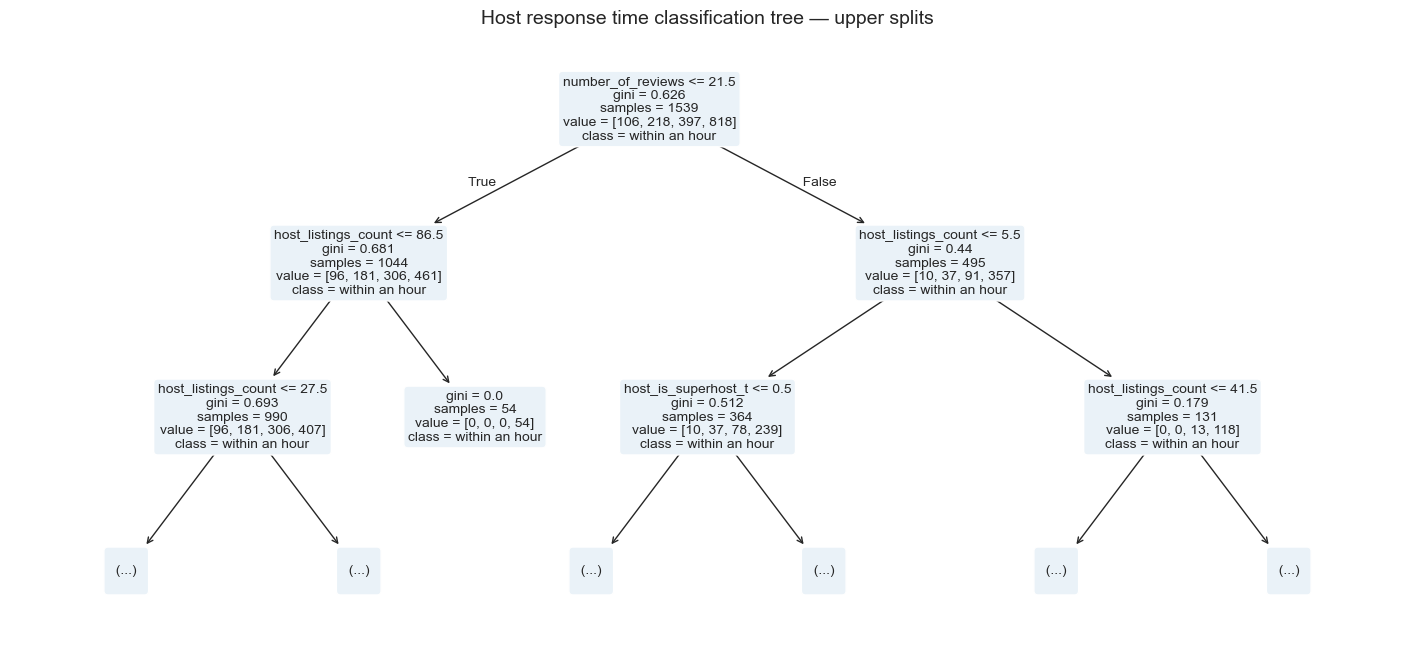

In [98]:
tree_feature_names = [name.split("__", 1)[-1] for name in final_tree.named_steps["preprocess"].get_feature_names_out()]

fig, ax = plt.subplots(figsize=(18, 8))

# Show the upper splits so the full-size tree is easier to interpret.
tree_nodes = plot_tree(fitted_tree,
                       max_depth=2,
                       feature_names=tree_feature_names,
                       class_names=fitted_tree.classes_.tolist(),
                       filled=True,
                       rounded=True,
                       fontsize=10,
                       ax=ax)

for node in tree_nodes:
    box = node.get_bbox_patch()
    if box is not None:
        box.set_facecolor("#EAF2F8")

ax.set_title("Host response time classification tree — upper splits", fontsize=14)
plt.show()

### What the tree shows

*Upper splits of the final classification tree (depth 20, 513 leaves). Boxes marked (…) indicate branches that continue below the portion shown.*

The tree first split listings by review count. In the training data, 44.2% of listings with 21 or fewer reviews had a host response time within an hour, compared with 72.1% of listings with 22 or more reviews. The tree then split both groups by the number of listings the host managed, using a different threshold in each group. This shows how the model used review count and host listing count together to distinguish response-time patterns.

### Our narrative

We trained a classification tree using the 1,924 listings with a recorded host response time. The predictors were guest capacity, room type, review count, Superhost status, and the host’s listing count. We kept the five listings with missing Superhost status by coding it as `unknown`. Because more than half of the listings were in the “within an hour” category, we used a stratified 80/20 split and compared tree depths using balanced accuracy in five-fold cross-validation. Depth 20 performed best among the depths tested, with a mean balanced accuracy of 38.70%.

On the test set, the tree had higher balanced accuracy than the majority-class baseline (38.91% versus 25.00%), while its overall accuracy was lower (50.13% versus 53.25%). It identified some listings in all four categories, including 6 of the 27 listings in the slowest category. The first split separated listings with 21 or fewer reviews from those with 22 or more. In the training data, 72.1% of listings with 22 or more reviews were in the “within an hour” category, compared with 44.2% of listings with 21 or fewer reviews.

## Part III. Transformer (`price_quartile`)

There is one important distinction: we are not really trying to predict the exact price prices here . We are trying to infer the likely price range from the language and features in the description.

### Splitting and creating classes

First step: build a separate dataframe for this part so we do not change `df` used above. On that copy, split `price` into four quartiles and store them in `price_quartile`.

In [ ]:
# separate frame for the transformer part (leave main df alone)
transformer_df = df.copy()

quartile_labels = ['lower', 'mid-low', 'mid-high', 'higher']
quartile_colors = {
    'lower': '#8ECAE6',
    'mid-low': '#219EBC',
    'mid-high': '#023047',
    'higher': '#FB8500',
}

transformer_df['price_quartile'] = pd.qcut(
    transformer_df['price'],
    q=4,
    labels=quartile_labels,
)

q_summary = (
    transformer_df.groupby('price_quartile', observed=True)['price']
    .agg(min_price='min', max_price='max', n='count')
    .reindex(quartile_labels)
)
counts = transformer_df['price_quartile'].value_counts().reindex(quartile_labels)

print('rows:', len(transformer_df))
print(q_summary)

# viz: capped price so the 25k outlier does not crush the chart
price_cap = transformer_df['price'].quantile(0.95)
plot_df = transformer_df.copy()
plot_df['price_plot'] = plot_df['price'].clip(upper=price_cap)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor('#F5F8FA')
for ax in axes:
    ax.set_facecolor('#F5F8FA')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.spines['left'].set_color('#5C5C5C')
    ax.spines['bottom'].set_color('#5C5C5C')
    ax.tick_params(colors='#333333')

# left: how many listings per quartile
bars = axes[0].bar(
    counts.index.astype(str),
    counts.values,
    color=[quartile_colors[q] for q in quartile_labels],
    edgecolor='white',
    width=0.72,
)
axes[0].set_title('Listings per price quartile', fontsize=14, fontweight='bold',
                  fontfamily='DejaVu Sans', color='#1a1a1a', pad=12)
axes[0].set_ylabel('Number of listings', fontsize=11, fontfamily='DejaVu Sans')
axes[0].set_xlabel('price_quartile', fontsize=11, fontfamily='DejaVu Sans')
axes[0].set_ylim(0, counts.max() * 1.15)
for bar, n, q in zip(bars, counts.values, quartile_labels):
    lo, hi = q_summary.loc[q, 'min_price'], q_summary.loc[q, 'max_price']
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 12,
        f'{int(n)}\nCHF {lo:.0f}-{hi:.0f}',
        ha='center', va='bottom', fontsize=9,
        fontfamily='DejaVu Sans', color='#333333',
    )

# right: price distribution within each quartile (95th-pct capped)
sns.boxplot(
    data=plot_df,
    x='price_quartile',
    y='price_plot',
    hue='price_quartile',
    order=quartile_labels,
    palette=quartile_colors,
    width=0.55,
    fliersize=2,
    linewidth=1.1,
    legend=False,
    ax=axes[1],
)
axes[1].set_title('Price spread inside each quartile', fontsize=14, fontweight='bold',
                  fontfamily='DejaVu Sans', color='#1a1a1a', pad=12)
axes[1].set_ylabel(f'Price (CHF, capped at {price_cap:.0f})', fontsize=11,
                    fontfamily='DejaVu Sans')
axes[1].set_xlabel('price_quartile', fontsize=11, fontfamily='DejaVu Sans')

fig.suptitle(
    'Geneva Airbnb: price_quartile (4 equal-count bins)',
    fontsize=16, fontweight='bold', fontfamily='DejaVu Sans',
    color='#023047', y=1.02,
)
plt.tight_layout()
plt.show()

print('\nsample:')
print(transformer_df[['price', 'price_quartile']].head(10))

One thing to note: the higher quartile has much more price spread than the others (about CHF 164 up to extreme outliers). Quartiles give equal counts, not equal price ranges, so that top bin mixes “a bit expensive” with luxury places. That can make the higher class harder to predict cleanly later.


### Building the Model

For the transformer part, after looking around on Hugging Face, we went with intfloat/multilingual-e5-base. A lot of the obvious models are English-only, and our Geneva listings are French, English, or a mix of both. This one covers that, we can actually run it in our current setup, and it felt like a better pick than the default BERT most people grab. We passed on a couple of newer ones: one needs a Google license click before you can download it, and another is basically English only.

The transformer does not name a price bin by itself. For each listing we stick the description, the host bio, and the amenity list into one text. E5 turns that text into a vector of 768 numbers. Those numbers are a short summary of what the text is about. In the logistic formula, each of those 768 numbers is a feature. The words are not the features. The transformer already mixed them into the vector.

Then a small logistic regression reads that vector and gives four probabilities: lower, mid-low, mid-high, and higher. We only train this small piece on our labeled listings. The big model stays frozen. Training just means learning which kinds of text tend to land in which price group. If the wording never really says why a place is expensive, the model cannot invent that.

In [ ]:
display(Image(filename='transformer_mental_model.png'))


### 1. One text per listing

The model takes one text input, so I join `description`, `host_about`, and `amenities` into `listing_text`. Airbnb descriptions have HTML tags (`<br>`, `<b>`), so I strip those first. A missing host bio stays blank. I do not drop the row, because about half the listings have no `host_about` and we still have the other two fields.


In [ ]:
def clean_listing_text(value):
    if pd.isna(value):
        return ''
    text = str(value)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = text.replace('&amp;', '&').replace('&nbsp;', ' ')
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def build_listing_text(description, host_about, amenities):
    return (
        'Description: ' + clean_listing_text(description)
        + ' Host: ' + clean_listing_text(host_about)
        + ' Amenities: ' + clean_listing_text(amenities)
    )

transformer_df['listing_text'] = [
    build_listing_text(d, h, a)
    for d, h, a in zip(
        transformer_df['description'],
        transformer_df['host_about'],
        transformer_df['amenities'],
    )
]

# keep rows that still have some real text and a price bin
has_text = transformer_df['listing_text'].str.len() > len('Description:  Host:  Amenities: ')
text_df = transformer_df.loc[has_text, ['listing_text', 'price', 'price_quartile']].copy()

print('rows used:', len(text_df))
print(text_df['listing_text'].iloc[0][:400])


### 2. Train/test split, then the frozen transformer

I split 80/20 and stratify on `price_quartile`, so each bin stays about a quarter of both sides. Quartiles are already fairly balanced, unlike the laundry outcome in KNN.

E5 does not get retrained. Each listing text goes in with a `query: ` prefix, which is how this model was trained when the vector is used as a feature. Out comes one vector of 768 numbers per listing.


In [ ]:
text_train, text_test, y_train_q, y_test_q = train_test_split(
    text_df['listing_text'],
    text_df['price_quartile'].astype(str),
    test_size=0.20,
    random_state=42,
    stratify=text_df['price_quartile'].astype(str),
)

print('train:', len(text_train), '| test:', len(text_test))
print(y_train_q.value_counts().reindex(quartile_labels))

e5_model = SentenceTransformer('intfloat/multilingual-e5-base', device='cpu')

X_train_emb = e5_model.encode(
    ['query: ' + t for t in text_train],
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True,
)
X_test_emb = e5_model.encode(
    ['query: ' + t for t in text_test],
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True,
)

print('train vectors:', X_train_emb.shape, '| test vectors:', X_test_emb.shape)


### 3. Logistic head

The 768 numbers are the features. Logistic regression learns a weight for each of them, per price bin: `z = b + w · x`. Softmax turns those four scores into probabilities. We fit this head on the training vectors only.


In [ ]:
price_clf = LogisticRegression(max_iter=1000, random_state=42)
price_clf.fit(X_train_emb, y_train_q)

train_pred = price_clf.predict(X_train_emb)
test_pred = price_clf.predict(X_test_emb)

print('Train accuracy:', round(accuracy_score(y_train_q, train_pred), 3))
print('Test accuracy: ', round(accuracy_score(y_test_q, test_pred), 3))
print('Chance level (4 balanced bins): about 0.25')

print('\nTrain classification report:')
print(classification_report(y_train_q, train_pred, digits=3))
print('Test classification report:')
print(classification_report(y_test_q, test_pred, digits=3))

test_cm = confusion_matrix(y_test_q, test_pred, labels=quartile_labels)
fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(
    test_cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=quartile_labels, yticklabels=quartile_labels,
    cbar=False, linewidths=1.1, linecolor='white',
    annot_kws={'size': 12, 'weight': 'bold'},
    ax=ax,
)
ax.set_xlabel('Predicted quartile')
ax.set_ylabel('True quartile')
ax.set_title('Test set: price quartile')
plt.tight_layout()
plt.show()


### 4. A fictional listing

Same three fields, same cleaning, same `query: ` prefix, same logistic head.


In [ ]:
fictional_price = 180  # CHF / night, made up for this example

# same quartile cuts as the real listings
_, quartile_edges = pd.qcut(
    transformer_df['price'], q=4, retbins=True, labels=quartile_labels
)
fictional_true = pd.cut(
    [fictional_price],
    bins=quartile_edges,
    labels=quartile_labels,
    include_lowest=True,
)[0]

fictional_examples = {
    'English': build_listing_text(
        description=(
            'Bright two-bedroom apartment in Eaux-Vives, a short walk from the lake. '
            'Renovated kitchen, large windows, quiet street.'
        ),
        host_about='I live in Geneva and host the apartment when I am away.',
        amenities='Wifi, Kitchen, Washer, Heating, Coffee maker, Dedicated workspace',
    ),
    'French': build_listing_text(
        description=(
            'Appartement lumineux de deux chambres à Eaux-Vives, à quelques minutes à pied du lac. '
            'Cuisine rénovée, grandes fenêtres, rue calme.'
        ),
        host_about="J'habite à Genève et je loue l'appartement quand je suis absent.",
        amenities='Wifi, Cuisine, Lave-linge, Chauffage, Machine à café, Espace de travail dédié',
    ),
}

for language, fictional_text in fictional_examples.items():
    fictional_vec = e5_model.encode(
        ['query: ' + fictional_text],
        normalize_embeddings=True,
    )
    fictional_pred = price_clf.predict(fictional_vec)[0]
    fictional_proba = price_clf.predict_proba(fictional_vec)[0]

    print('---', language, '---')
    print(fictional_text)
    print('Made-up price: CHF', fictional_price)
    print('True quartile:     ', fictional_true)
    print('Predicted quartile:', fictional_pred)
    for label, prob in sorted(zip(price_clf.classes_, fictional_proba), key=lambda x: -x[1]):
        print(f'  {label:8} {prob:.3f}')
    print()


### Narrative

We joined description, host_about, and amenities into one text per listing, after stripping HTML tags from the Airbnb descriptions. Missing host bios were left blank instead of dropping the row. We held out 20% of the listings, with the same mix of price quartiles in train and test. `multilingual-e5-base` stayed frozen: each text became a vector of 768 numbers, and a logistic regression used those numbers as features to score the four bins.

On the training set the head is right about 52% of the time. On the test set that falls to about 43%. A guess with no text would be about 25%, so the wording does carry some price signal, but not a strong one. The model is better at the two ends (`lower` and `higher`) than at the two middle bins, which sit close together. The fictional Eaux-Vives apartment is called `mid-high`, but the four probabilities are almost even (about 0.23 to 0.26), so that call is not a confident one. Text alone does not pin down a Geneva price quartile very tightly.


### Things to acknowledge

`host_about` is blank for 1,244 of 2,458 listings (about half). `description` is blank for only 61, and `amenities` is never blank. We left the missing bios empty instead of dropping the rows or inventing text. Almost all of those listings still have a description, so the concatenated text is not empty.

The `higher` quartile is also much wider than the others. It starts around CHF 164 and runs up to extreme outliers, so "a bit expensive" and luxury sit in the same bin. Quartiles keep the counts equal, not the price ranges.

Two smaller limits. The model is better at the two end bins than at `mid-low` and `mid-high`. And train accuracy (about 0.52) is higher than test accuracy (about 0.43), so the head fits the training listings a bit more tightly than new ones. Text alone is only a modest signal for price.


# Part 4. Clustering

### Checking the clustering features

The goal is to use k-means to group Geneva Airbnb listings with similar characteristics. I started by looking at guest capacity, bedroom count, bed count, and listed price. I checked missing values and summary statistics to decide which features to use and how to prepare them before clustering.

In [99]:
# Use a separate dataframe for clustering.
clustering_raw_df = pd.read_csv(Path("geneva_listings.csv"))

# Convert the listed prices to numbers for the summary and clustering.
clustering_raw_df["price"] = (clustering_raw_df["price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float))

clustering_candidates = ["accommodates", "bedrooms", "beds", "price"]

print("Missing values in candidate features")
print(clustering_raw_df[clustering_candidates].isna().sum())

print("\nSummary statistics")
print(clustering_raw_df[clustering_candidates].describe().round(2))

Missing values in candidate features
accommodates      0
bedrooms        842
beds             35
price             0
dtype: int64

Summary statistics
       accommodates  bedrooms     beds     price
count       2458.00   1616.00  2423.00   2458.00
mean           2.68      1.46     1.60    174.02
std            1.55      0.83     1.06    611.11
min            1.00      1.00     1.00     20.00
25%            2.00      1.00     1.00     82.00
50%            2.00      1.00     1.00    114.50
75%            4.00      2.00     2.00    163.00
max           16.00      9.00    16.00  25000.00


Bedroom count was missing for 842 listings, about one-third of the dataset, so I left it out. Bed count was missing for only 35 listings, so I kept that feature and excluded those rows. That left 2,423 listings for clustering.

The median price was CHF 114.50, while the maximum was CHF 25,000. I used log price to reduce the influence of this wide price range. I standardized guest capacity, bed count, and log price so that the distances used by k-means would put the three features on a comparable scale.

In [103]:
# Keep listings with a recorded bed count and use log price for clustering.
cluster_df = clustering_raw_df.dropna(subset=["beds"]).copy()
cluster_df["log_price"] = np.log(cluster_df["price"])

cluster_features = ["accommodates", "beds", "log_price"]
cluster_X_scaled = StandardScaler().fit_transform(cluster_df[cluster_features])

# Compare how well the listings group together for different values of k.
cluster_k_results = []

for k in range(2, 7):
    kmeans_model = KMeans(n_clusters=k, n_init=20, random_state=42)
    cluster_labels = kmeans_model.fit_predict(cluster_X_scaled)
    cluster_k_results.append({"k": k,
                              "Silhouette score": silhouette_score(cluster_X_scaled, cluster_labels)})

print("Listings used for clustering:", len(cluster_df))
print(pd.DataFrame(cluster_k_results).round(4).to_string(index=False))

Listings used for clustering: 2423
 k  Silhouette score
 2            0.5020
 3            0.4666
 4            0.3317
 5            0.3429
 6            0.3627


### Choosing the number of clusters

I compared solutions with two to six clusters using the silhouette score, which measures how close listings are to their own cluster relative to the nearest other cluster. The two-cluster solution scored highest among the options tested (0.5020), followed by the three-cluster solution (0.4666). I chose two clusters and then looked at the median guest capacity, bed count, and listed price to see what distinguished the two groups.

In [104]:
# Fit the selected two-cluster model.
final_kmeans = KMeans(n_clusters=2, n_init=20, random_state=42)
cluster_df["cluster"] = final_kmeans.fit_predict(cluster_X_scaled)

# Summarize the listings in their original units for interpretation.
cluster_summary = cluster_df.groupby("cluster").agg(listings=("price", "size"),
                                                    median_guests=("accommodates", "median"),
                                                    median_beds=("beds", "median"),
                                                    median_price_chf=("price", "median"))
cluster_summary["share_pct"] = (100 * cluster_summary["listings"] / len(cluster_df))

print("Cluster profiles")
print(cluster_summary.round(2).to_string())

Cluster profiles
         listings  median_guests  median_beds  median_price_chf  share_pct
cluster                                                                   
0             690            4.0          2.0             187.0      28.48
1            1733            2.0          1.0              99.0      71.52


### Naming and describing the clusters

I called Cluster 0 **Larger, higher-priced listings** because its median listing accommodated four guests, had two beds, and was priced at CHF 187. This group contained 690 listings, or 28.5% of the listings analyzed.

I called Cluster 1 **Smaller, lower-priced listings**. It contained 1,733 listings (71.5%), with medians of two guests, one bed, and CHF 99. These names describe the typical listing in each cluster. To see how much the listings varied within each group, I next compared their capacity and price distributions.

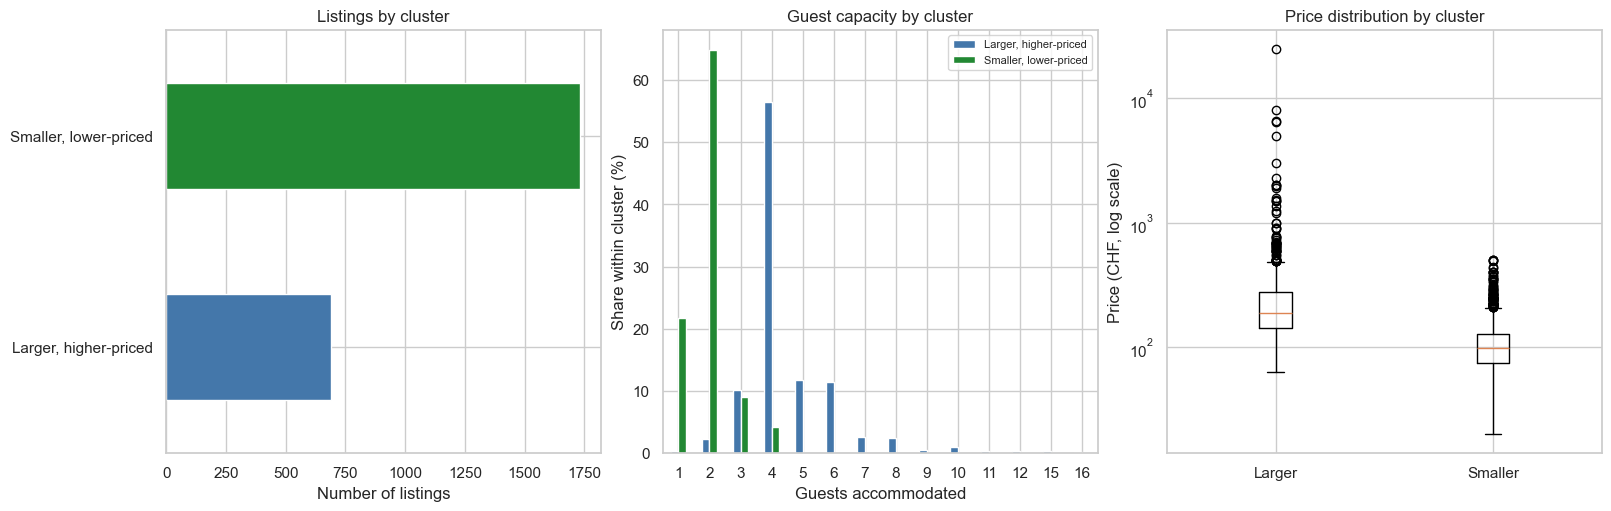

In [105]:
cluster_names = {0: "Larger, higher-priced",
                 1: "Smaller, lower-priced"}
cluster_df["cluster_name"] = cluster_df["cluster"].map(cluster_names)
cluster_order = list(cluster_names.values())
cluster_colors = ["#4477AA", "#228833"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)

# Show how many listings belong to each cluster.
cluster_counts = cluster_df["cluster_name"].value_counts().reindex(cluster_order)
cluster_counts.plot.barh(ax=axes[0], color=cluster_colors)
axes[0].set_title("Listings by cluster")
axes[0].set_xlabel("Number of listings")
axes[0].set_ylabel("")

# Use within-cluster percentages to compare groups of different sizes.
capacity_pct = pd.crosstab(cluster_df["accommodates"],
                           cluster_df["cluster_name"],
                           normalize="columns").reindex(columns=cluster_order) * 100

capacity_pct.plot.bar(ax=axes[1], color=cluster_colors)
axes[1].set_title("Guest capacity by cluster")
axes[1].set_xlabel("Guests accommodated")
axes[1].set_ylabel("Share within cluster (%)")
axes[1].tick_params(axis="x", labelrotation=0)
axes[1].legend(fontsize=8)

# Use a log axis so both typical prices and extreme values are visible.
prices_by_cluster = [cluster_df.loc[cluster_df["cluster_name"] == name, "price"]
                     for name in cluster_order]

axes[2].boxplot(prices_by_cluster)
axes[2].set_xticks([1, 2])
axes[2].set_xticklabels(["Larger", "Smaller"])
axes[2].set_yscale("log")
axes[2].set_title("Price distribution by cluster")
axes[2].set_ylabel("Price (CHF, log scale)")

plt.show()

### What the plots show

1. **Listings by cluster.** The smaller, lower-priced cluster accounted for 1,733 of the 2,423 listings (71.5%). The larger, higher-priced cluster contained the remaining 690 listings (28.5%).
2. **Guest capacity by cluster.** Two guests was the most common capacity in the smaller cluster, while four guests was the most common in the larger cluster. The bars show percentages within each cluster, so the groups can be compared despite their different sizes.
3. **Price distribution by cluster.** The median price was CHF 187 in the larger cluster and CHF 99 in the smaller cluster. The price ranges overlapped, and the larger cluster contained the highest-priced listings. The vertical axis uses a logarithmic scale.

### Our narrative

We used k-means to group Geneva Airbnb listings based on guest capacity, bed count, and listed price. We left out bedroom count because it was missing for 842 listings. We excluded the 35 listings with missing bed counts, leaving 2,423 for the analysis. Because prices were strongly right-skewed, we used log price and standardized all three features before fitting the model. We compared solutions with two to six clusters and chose two because that solution had the highest silhouette score among those tested (0.5020).

The smaller, lower-priced cluster accounted for 71.5% of the listings and had medians of two guests, one bed, and CHF 99. The larger, higher-priced cluster had medians of four guests, two beds, and CHF 187. The capacity plot showed that two and four guests were the most common capacities in the respective groups. The boxplots showed some overlap in prices, so the cluster names describe typical listings in each group rather than a fixed price cutoff.

# Part 5. Conclusions

*(to do)*
